<a href="https://colab.research.google.com/github/VijayReddy-07/Token-Analytics/blob/main/Token_Analytics_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np
import os

from pathlib import Path

In [3]:
DATA_PATH = Path(
    "/content/drive/MyDrive/Token-Analytics/data/raw"
)

print("Dataset folder exists:", DATA_PATH.exists())

Dataset folder exists: True


In [4]:
csv_files = list(DATA_PATH.rglob("*.csv"))

print("Total CSV files found:", len(csv_files))

for file in csv_files:
    print(file.name)

Total CSV files found: 9
users.csv
requests.csv
projects.csv
models.csv
llm_system_users_summary.csv
llm_system_sessions_summary.csv
llm_system_prompts_lookup.csv
llm_system_interactions.csv
llm_system_instruction_tuning_samples.csv


In [5]:
datasets = {}

for file in csv_files:

    df = pd.read_csv(file)

    datasets[file.stem] = df

    print(f"Loaded: {file.name}")
    print(f"Rows: {df.shape[0]}")
    print(f"Columns: {df.shape[1]}")
    print("-" * 50)

Loaded: users.csv
Rows: 60
Columns: 6
--------------------------------------------------
Loaded: requests.csv
Rows: 1000
Columns: 16
--------------------------------------------------
Loaded: projects.csv
Rows: 10
Columns: 5
--------------------------------------------------
Loaded: models.csv
Rows: 6
Columns: 7
--------------------------------------------------
Loaded: llm_system_users_summary.csv
Rows: 438
Columns: 21
--------------------------------------------------
Loaded: llm_system_sessions_summary.csv
Rows: 1595
Columns: 37
--------------------------------------------------
Loaded: llm_system_prompts_lookup.csv
Rows: 36
Columns: 14
--------------------------------------------------
Loaded: llm_system_interactions.csv
Rows: 9000
Columns: 55
--------------------------------------------------
Loaded: llm_system_instruction_tuning_samples.csv
Rows: 9000
Columns: 16
--------------------------------------------------


In [6]:
df = datasets["llm_system_interactions"]

display(df.head(10))

,interaction_id,session_id,user_id,timestamp_utc,split,channel,use_case,country_code,region,account_tier,...,day_of_week,is_weekend,is_peak_hour,prompt_to_completion_ratio,request_text_template,instruction_text,user_feedback_observed,prompt_id,response_text_snippet_len_chars,response_text_snippet_is_truncated
0,INT000001,S01207,U00013,2025-03-25T11:14:35Z,train,web_app,coding_assistant,BR,AMER,pro,...,1,False,True,0.4408,I'm getting a Python error: `NullPointerExcept...,You are a senior software engineer helping use...,True,83c939e9b891e505ac06548e158556e919317a64,216,True
1,INT000002,S01119,U00017,2025-02-23T04:08:56Z,val,mobile_app,customer_support,IN,APAC,free,...,6,True,False,1.7098,Our customer is getting an error when trying t...,You are a helpful customer support assistant f...,False,a52fb80193c7c0769c0836852624f4b025a04d2a,207,True
2,INT000003,S00653,U00155,2025-02-25T17:31:08Z,train,web_app,brainstorming,GB,EMEA,free,...,1,False,True,3.2443,Brainstorm taglines for a productivity app tha...,You are a creative assistant helping users exp...,False,9886b059d7fa547dc6fd91d4a5c80abdb317022d,223,True
3,INT000004,S00103,U00263,2025-03-14T17:42:16Z,train,web_app,content_writing,AU,APAC,free,...,4,False,True,2.1523,Draft a friendly email announcing a small pric...,You are a writing assistant helping users craf...,False,469eb15f8b08d9b4130e14a6c3888f14e335a854,236,True
4,INT000005,S01553,U00118,2025-02-24T00:39:04Z,train,api,data_analysis,IN,APAC,enterprise,...,0,False,False,0.1508,I have a CSV with user sessions. Show me a qui...,You are a data analysis assistant helping user...,True,a15ac130f4f428f0efac738d5c68655674fccc6e,251,True
5,INT000006,S00993,U00038,2025-02-21T08:23:26Z,train,api,customer_support,GB,EMEA,free,...,4,False,False,3.3117,"Hi, I'm having an issue with my billing. The i...",You are a helpful customer support assistant f...,False,a52fb80193c7c0769c0836852624f4b025a04d2a,244,True
6,INT000007,S00928,U00216,2025-02-21T07:15:08Z,train,web_app,content_writing,IN,APAC,enterprise,...,4,False,False,0.5564,Rewrite this paragraph in a clearer and more p...,You are a writing assistant helping users craf...,True,75b7366387b6cf4f5631ec9dd298a359e5bb9c1d,250,True
7,INT000008,S01286,U00160,2025-02-05T15:31:31Z,train,api,customer_support,EG,EMEA,enterprise,...,2,False,True,19.2000,"Hi, I'm having an issue with my billing. The i...",You are a helpful customer support assistant f...,False,d029d0919f8e306d09ca7001d500c1e6f1c81007,216,True
8,INT000009,S00864,U00414,2025-04-16T16:52:44Z,train,api,brainstorming,GB,EMEA,free,...,2,False,True,2.9217,Give me ten creative ideas for a YouTube serie...,You are a creative assistant helping users exp...,True,9886b059d7fa547dc6fd91d4a5c80abdb317022d,244,True
9,INT000010,S01003,U00017,2025-03-28T10:07:54Z,train,internal_tool,internal_qa,IN,APAC,free,...,4,False,True,3.3860,Follow-up: the previous reply did not fully so...,You are an internal knowledge assistant helpin...,False,4e3bb3b7c597daf93de3f611632f4c56cefdec0e,198,True


In [7]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Dataset Shape:
(9000, 55)

Column Names:
['interaction_id', 'session_id', 'user_id', 'timestamp_utc', 'split', 'channel', 'use_case', 'country_code', 'region', 'account_tier', 'segment', 'instruction_template', 'model_provider', 'model_name', 'temperature', 'top_p', 'max_tokens', 'prompt_tokens', 'completion_tokens', 'total_tokens', 'latency_ms', 'cost_usd', 'response_quality_score', 'is_failure', 'failure_type', 'hallucination_flag', 'toxicity_flag', 'safety_block_flag', 'formatting_error_flag', 'tool_error_flag', 'latency_timeout_flag', 'tool_calls_count', 'tools_used', 'user_feedback_score', 'user_feedback_label', 'user_reported_issue', 'retry_index', 'repair_strategy', 'final_resolution_state', 'business_impact_tag', 'request_text', 'response_text_snippet', 'tokens_per_second', 'date_utc', 'hour_of_day_utc', 'day_of_week', 'is_weekend', 'is_peak_hour', 'prompt_to_completion_ratio', 'request_text_template', 'instruction_text', 'user_feedback_observed', 'prompt_id', 'response_text_sn

In [8]:
# Create a separate copy of the original dataset

df_clean = df.copy()

print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)

Original dataset shape: (9000, 55)
Working dataset shape: (9000, 55)


In [9]:
# Calculate missing values in each column

missing_values = df_clean.isnull().sum()

# Calculate missing percentage

missing_percentage = (
    df_clean.isnull().mean() * 100
).round(2)

# Create a summary table

missing_summary = pd.DataFrame({
    "Missing Count": missing_values,
    "Missing Percentage": missing_percentage
})

# Display columns with missing values

display(
    missing_summary[
        missing_summary["Missing Count"] > 0
    ]
)

,Missing Count,Missing Percentage
user_feedback_score,4120,45.78


In [10]:
# Convert timestamp column to datetime

df_clean["timestamp_utc"] = pd.to_datetime(
    df_clean["timestamp_utc"],
    errors="coerce",
    utc=True
)

# Convert date column to datetime

df_clean["date_utc"] = pd.to_datetime(
    df_clean["date_utc"],
    errors="coerce"
)

# Display the converted data types

print(df_clean[
    ["timestamp_utc", "date_utc"]
].dtypes)

# Check invalid timestamps

print(
    "Invalid timestamps:",
    df_clean["timestamp_utc"].isna().sum()
)

timestamp_utc    datetime64[ns, UTC]
date_utc              datetime64[ns]
dtype: object
Invalid timestamps: 0


In [11]:
# Calculate expected total tokens

df_clean["calculated_total_tokens"] = (
    df_clean["prompt_tokens"]
    + df_clean["completion_tokens"]
)

# Compare calculated and recorded values

df_clean["token_mismatch"] = (
    df_clean["total_tokens"]
    != df_clean["calculated_total_tokens"]
)

# Display validation results

print(
    "Token mismatches:",
    df_clean["token_mismatch"].sum()
)

print(
    "Total recorded tokens:",
    df_clean["total_tokens"].sum()
)

print(
    "Total calculated tokens:",
    df_clean["calculated_total_tokens"].sum()
)

Token mismatches: 0
Total recorded tokens: 9842473
Total calculated tokens: 9842473


In [12]:
# Columns that should not contain negative values

numeric_columns = [
    "prompt_tokens",
    "completion_tokens",
    "total_tokens",
    "latency_ms",
    "cost_usd",
    "max_tokens",
    "tool_calls_count",
    "retry_index"
]

# Count negative values in each column

for column in numeric_columns:

    negative_count = (
        df_clean[column] < 0
    ).sum()

    print(
        column,
        "Negative values:",
        negative_count
    )

prompt_tokens Negative values: 0
completion_tokens Negative values: 0
total_tokens Negative values: 0
latency_ms Negative values: 0
cost_usd Negative values: 0
max_tokens Negative values: 0
tool_calls_count Negative values: 0
retry_index Negative values: 0


In [13]:
print(
    "Duplicate interaction IDs:",
    df_clean["interaction_id"].duplicated().sum()
)

print(
    "Unique interaction IDs:",
    df_clean["interaction_id"].nunique()
)

print(
    "Total records:",
    len(df_clean)
)

Duplicate interaction IDs: 0
Unique interaction IDs: 9000
Total records: 9000


In [14]:
categorical_columns = [
    "model_provider",
    "model_name",
    "use_case",
    "channel",
    "account_tier",
    "segment",
    "user_feedback_label",
    "final_resolution_state"
]

for column in categorical_columns:

    print("\nColumn:", column)

    print(
        df_clean[column].value_counts(
            dropna=False
        ).head(10)
    )


Column: model_provider
model_provider
meta         2306
openai       2247
local        1158
google       1114
mistral      1090
anthropic    1085
Name: count, dtype: int64

Column: model_name
model_name
llama-3.1-70b        1158
custom-local-8b      1158
gpt-4o-mini          1158
llama-3.1-8b         1148
gemini-1.5-pro       1114
mistral-large        1090
gpt-4.1              1089
claude-3.5-sonnet    1085
Name: count, dtype: int64

Column: use_case
use_case
customer_support    2723
coding_assistant    1681
data_analysis       1454
content_writing     1441
brainstorming        909
internal_qa          792
Name: count, dtype: int64

Column: channel
channel
web_app          3644
api              2260
mobile_app       1215
internal_tool     943
slack             938
Name: count, dtype: int64

Column: account_tier
account_tier
free          5007
pro           2532
enterprise    1461
Name: count, dtype: int64

Column: segment
segment
individual         4221
team               3087
enterpr

In [15]:
# Extract year, month, and hour from timestamp

df_clean["year"] = (
    df_clean["timestamp_utc"].dt.year
)

df_clean["month"] = (
    df_clean["timestamp_utc"].dt.month
)

df_clean["month_name"] = (
    df_clean["timestamp_utc"].dt.month_name()
)

df_clean["hour"] = (
    df_clean["timestamp_utc"].dt.hour
)

# Calculate input/output token percentage

df_clean["input_token_percentage"] = (
    df_clean["prompt_tokens"]
    / df_clean["total_tokens"].replace(0, np.nan)
) * 100

df_clean["output_token_percentage"] = (
    df_clean["completion_tokens"]
    / df_clean["total_tokens"].replace(0, np.nan)
) * 100

# Display newly created columns

display(
    df_clean[
        [
            "timestamp_utc",
            "year",
            "month",
            "month_name",
            "hour",
            "input_token_percentage",
            "output_token_percentage"
        ]
    ].head()
)

,timestamp_utc,year,month,month_name,hour,input_token_percentage,output_token_percentage
0,2025-03-25 11:14:35+00:00,2025,3,March,11,30.592105,69.407895
1,2025-02-23 04:08:56+00:00,2025,2,February,4,63.096310,36.903690
2,2025-02-25 17:31:08+00:00,2025,2,February,17,76.438849,23.561151
3,2025-03-14 17:42:16+00:00,2025,3,March,17,68.277066,31.722934
4,2025-02-24 00:39:04+00:00,2025,2,February,0,13.104839,86.895161


In [16]:
quality_report = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Total Columns",
        "Duplicate Rows",
        "Duplicate Interaction IDs",
        "Missing Feedback Scores",
        "Invalid Timestamps",
        "Token Mismatches",
        "Negative Token Values"
    ],
    "Value": [
        len(df_clean),
        len(df_clean.columns),
        df_clean.duplicated().sum(),
        df_clean["interaction_id"].duplicated().sum(),
        df_clean["user_feedback_score"].isna().sum(),
        df_clean["timestamp_utc"].isna().sum(),
        df_clean["token_mismatch"].sum(),
        (
            df_clean[
                ["prompt_tokens", "completion_tokens", "total_tokens"]
            ] < 0
        ).sum().sum()
    ]
})

display(quality_report)

,Metric,Value
0,Total Records,9000
1,Total Columns,63
2,Duplicate Rows,0
3,Duplicate Interaction IDs,0
4,Missing Feedback Scores,4120
5,Invalid Timestamps,0
6,Token Mismatches,0
7,Negative Token Values,0


In [17]:
# Create processed data folder

PROCESSED_PATH = (
    "/content/drive/MyDrive/Token-Analytics/data/processed"
)

os.makedirs(
    PROCESSED_PATH,
    exist_ok=True
)

# Save cleaned data as CSV

csv_output = os.path.join(
    PROCESSED_PATH,
    "cleaned_token_analytics.csv"
)

df_clean.to_csv(
    csv_output,
    index=False
)

# Save as Parquet for efficient future processing

parquet_output = os.path.join(
    PROCESSED_PATH,
    "cleaned_token_analytics.parquet"
)

df_clean.to_parquet(
    parquet_output,
    index=False
)

print("Cleaned datasets saved successfully!")
print(csv_output)
print(parquet_output)

Cleaned datasets saved successfully!
/content/drive/MyDrive/Token-Analytics/data/processed/cleaned_token_analytics.csv
/content/drive/MyDrive/Token-Analytics/data/processed/cleaned_token_analytics.parquet


In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [19]:
eda_df = df_clean.copy()

eda_df["timestamp_utc"] = pd.to_datetime(
    eda_df["timestamp_utc"],
    errors="coerce",
    utc=True
)

eda_df["date"] = eda_df["timestamp_utc"].dt.date
eda_df["month_year"] = eda_df["timestamp_utc"].dt.strftime("%Y-%m")

print("Dataset shape:", eda_df.shape)
display(eda_df.head())

Dataset shape: (9000, 65)


,interaction_id,session_id,user_id,timestamp_utc,split,channel,use_case,country_code,region,account_tier,segment,instruction_template,model_provider,model_name,temperature,top_p,max_tokens,prompt_tokens,completion_tokens,total_tokens,latency_ms,cost_usd,response_quality_score,is_failure,failure_type,hallucination_flag,toxicity_flag,safety_block_flag,formatting_error_flag,tool_error_flag,latency_timeout_flag,tool_calls_count,tools_used,user_feedback_score,user_feedback_label,user_reported_issue,retry_index,repair_strategy,final_resolution_state,business_impact_tag,request_text,response_text_snippet,tokens_per_second,date_utc,hour_of_day_utc,day_of_week,is_weekend,is_peak_hour,prompt_to_completion_ratio,request_text_template,instruction_text,user_feedback_observed,prompt_id,response_text_snippet_len_chars,response_text_snippet_is_truncated,calculated_total_tokens,token_mismatch,year,month,month_name,hour,input_token_percentage,output_token_percentage,date,month_year
0,INT000001,S01207,U00013,2025-03-25 11:14:35+00:00,train,web_app,coding_assistant,BR,AMER,pro,enterprise_team,creative_writer,meta,llama-3.1-70b,0.257,0.898,768,186,422,608,615,0.12160,0.846,False,none,False,False,False,False,False,False,0,none,2.0,positive,False,0,none,auto_resolved,medium,Can you help me debug this? I'm getting a Pyth...,Let's turn this into a reliable workflow. Goal...,988.617886,2025-03-25,11,1,False,True,0.4408,I'm getting a Python error: `NullPointerExcept...,You are a senior software engineer helping use...,True,83c939e9b891e505ac06548e158556e919317a64,216,True,608,False,2025,3,March,11,30.592105,69.407895,2025-03-25,2025-03
1,INT000002,S01119,U00017,2025-02-23 04:08:56+00:00,val,mobile_app,customer_support,IN,APAC,free,individual,general_assistant,anthropic,claude-3.5-sonnet,0.806,0.890,768,701,410,1111,1194,0.35552,0.352,True,formatting_error,False,False,False,True,False,False,0,none,NaN,no_feedback,False,0,enable_tools,escalated_to_human,high,I'm stuck on this and need some guidance: Our ...,Let's break this down into actionable steps. S...,930.485762,2025-02-23,4,6,True,False,1.7098,Our customer is getting an error when trying t...,You are a helpful customer support assistant f...,False,a52fb80193c7c0769c0836852624f4b025a04d2a,207,True,1111,False,2025,2,February,4,63.096310,36.903690,2025-02-23,2025-02
2,INT000003,S00653,U00155,2025-02-25 17:31:08+00:00,train,web_app,brainstorming,GB,EMEA,free,team,code_assistant_secure,google,gemini-1.5-pro,0.412,0.898,1024,425,131,556,1196,0.17792,0.543,True,safety_block,False,False,True,False,False,False,0,none,NaN,no_feedback,False,0,manual_post_edit,abandoned,low,Context for you: Brainstorm taglines for a pro...,This is a common pattern; the fix is straightf...,464.882943,2025-02-25,17,1,False,True,3.2443,Brainstorm taglines for a productivity app tha...,You are a creative assistant helping users exp...,False,9886b059d7fa547dc6fd91d4a5c80abdb317022d,223,True,556,False,2025,2,February,17,76.438849,23.561151,2025-02-25,2025-02
3,INT000004,S00103,U00263,2025-03-14 17:42:16+00:00,train,web_app,content_writing,AU,APAC,free,team,creative_writer,google,gemini-1.5-pro,0.637,0.822,1024,1173,545,1718,1266,0.54976,0.888,False,none,False,False,False,False,False,False,0,none,NaN,no_feedback,False,0,none,auto_resolved,high,I'm working on something and need help: Draft ...,Here's what I'd implement in production. Goal:...,1357.030016,2025-03-14,17,4,False,True,2.1523,Draft a friendly email announcing a small pric...,You are a writing assistant helping users craf...,False,469eb15f8b08d9b4130e14a6c3888f14e335a854,236,True,1718,False,2025,3,March,17,68.277066,31.722934,2025-03-14,2025-03
4,INT000005,S01553,U00118,2025-02-24 00:39:04+00:00,train,api,data_analysis,IN,APAC,enterprise,individual,support_strict,meta,llama-3.1-8b,0.414,0.949,512,65,431,496,833,0.02976,0.755,False,none,False,False,False,False,False,False,2,email_send|knowledge_lookup,0.0,neutral,False,0,none,auto_resolved,low,Quick question: I have a CSV wit

In [20]:
total_requests = len(eda_df)
total_tokens = eda_df["total_tokens"].sum()
prompt_tokens = eda_df["prompt_tokens"].sum()
completion_tokens = eda_df["completion_tokens"].sum()
total_cost = eda_df["cost_usd"].sum()

average_latency = eda_df["latency_ms"].mean()
average_tokens = eda_df["total_tokens"].mean()

failed_requests = eda_df["is_failure"].sum()
failure_rate = (failed_requests / total_requests) * 100

unique_users = eda_df["user_id"].nunique()
unique_models = eda_df["model_name"].nunique()

kpi_summary = pd.DataFrame({
    "Metric": [
        "Total API Requests",
        "Total Tokens",
        "Prompt Tokens",
        "Completion Tokens",
        "Total Estimated Cost (USD)",
        "Average Latency (ms)",
        "Average Tokens per Request",
        "Failed Requests",
        "Failure Rate (%)",
        "Unique Users",
        "Models Used"
    ],
    "Value": [
        total_requests,
        total_tokens,
        prompt_tokens,
        completion_tokens,
        round(total_cost, 4),
        round(average_latency, 2),
        round(average_tokens, 2),
        failed_requests,
        round(failure_rate, 2),
        unique_users,
        unique_models
    ]
})

display(kpi_summary)

,Metric,Value
0,Total API Requests,9.000000e+03
1,Total Tokens,9.842473e+06
2,Prompt Tokens,6.328824e+06
3,Completion Tokens,3.513649e+06
4,Total Estimated Cost (USD),1.748190e+03
5,Average Latency (ms),1.215250e+03
6,Average Tokens per Request,1.093610e+03
7,Failed Requests,2.557000e+03
8,Failure Rate (%),2.841000e+01
9,Unique Users,4.380000e+02


In [21]:
model_usage = (
    eda_df.groupby("model_name")
    .agg(
        Total_Requests=("interaction_id", "count"),
        Total_Tokens=("total_tokens", "sum"),
        Total_Cost=("cost_usd", "sum"),
        Average_Latency=("latency_ms", "mean")
    )
    .reset_index()
    .sort_values("Total_Requests", ascending=False)
)

display(model_usage)

,model_name,Total_Requests,Total_Tokens,Total_Cost,Average_Latency
1,custom-local-8b,1158,1259629,5.03928,1245.862694
4,gpt-4o-mini,1158,1265778,25.31832,1204.274611
5,llama-3.1-70b,1158,1275683,255.13660,1192.372193
6,llama-3.1-8b,1148,1253796,75.22960,1220.916376
2,gemini-1.5-pro,1114,1218567,389.94144,1191.526930
7,mistral-large,1090,1195366,143.44392,1204.374312
3,gpt-4.1,1089,1181396,472.55840,1221.167126
0,claude-3.5-sonnet,1085,1192258,381.52256,1242.034101


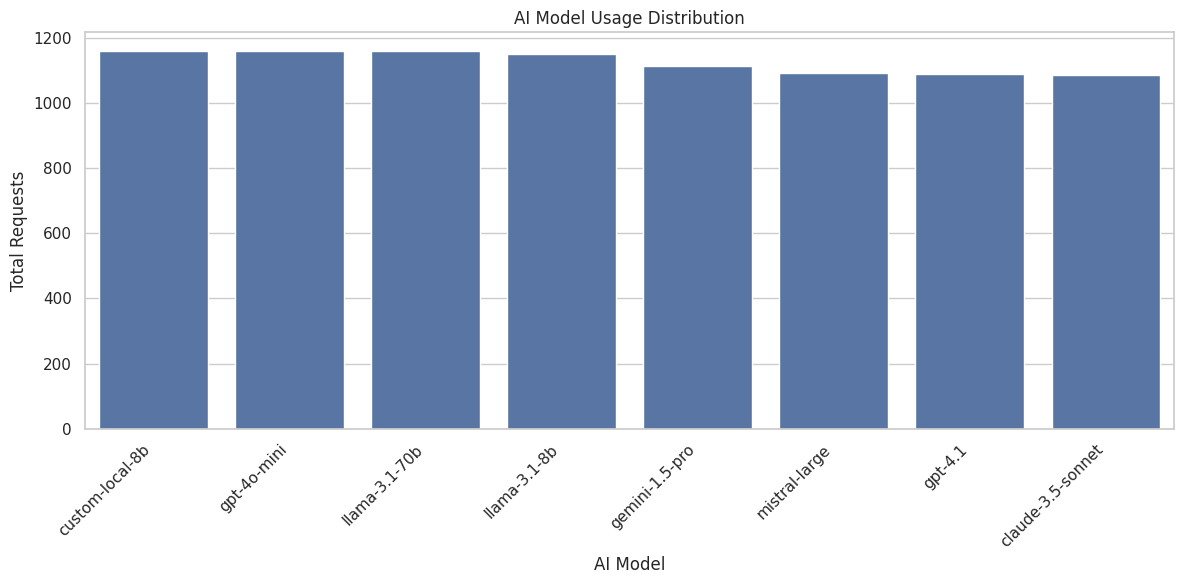

In [22]:
plt.figure(figsize=(12, 6))
sns.barplot(data=model_usage, x="model_name", y="Total_Requests")

plt.title("AI Model Usage Distribution")
plt.xlabel("AI Model")
plt.ylabel("Total Requests")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [23]:
token_analysis = (
    eda_df.groupby("model_name")
    .agg(
        Prompt_Tokens=("prompt_tokens", "sum"),
        Completion_Tokens=("completion_tokens", "sum"),
        Total_Tokens=("total_tokens", "sum")
    )
    .reset_index()
    .sort_values("Total_Tokens", ascending=False)
)

display(token_analysis)

,model_name,Prompt_Tokens,Completion_Tokens,Total_Tokens
5,llama-3.1-70b,816663,459020,1275683
4,gpt-4o-mini,810075,455703,1265778
1,custom-local-8b,813829,445800,1259629
6,llama-3.1-8b,802393,451403,1253796
2,gemini-1.5-pro,791347,427220,1218567
7,mistral-large,767753,427613,1195366
0,claude-3.5-sonnet,772609,419649,1192258
3,gpt-4.1,754155,427241,1181396


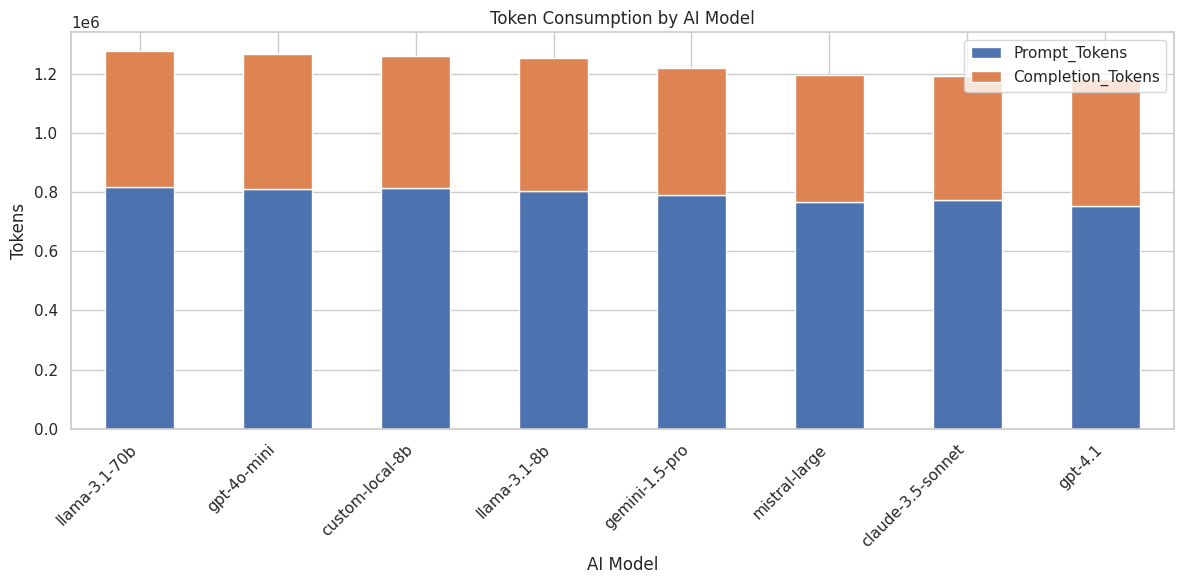

In [24]:
token_plot = token_analysis.set_index("model_name")[
    ["Prompt_Tokens", "Completion_Tokens"]
]

token_plot.plot(kind="bar", stacked=True, figsize=(12, 6))

plt.title("Token Consumption by AI Model")
plt.xlabel("AI Model")
plt.ylabel("Tokens")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [25]:
cost_by_model = (
    eda_df.groupby("model_name")
    .agg(
        Total_Cost=("cost_usd", "sum"),
        Average_Cost=("cost_usd", "mean"),
        Total_Requests=("interaction_id", "count")
    )
    .reset_index()
    .sort_values("Total_Cost", ascending=False)
)

display(cost_by_model)

,model_name,Total_Cost,Average_Cost,Total_Requests
3,gpt-4.1,472.55840,0.433938,1089
2,gemini-1.5-pro,389.94144,0.350037,1114
0,claude-3.5-sonnet,381.52256,0.351634,1085
5,llama-3.1-70b,255.13660,0.220325,1158
7,mistral-large,143.44392,0.131600,1090
6,llama-3.1-8b,75.22960,0.065531,1148
4,gpt-4o-mini,25.31832,0.021864,1158
1,custom-local-8b,5.03928,0.004352,1158


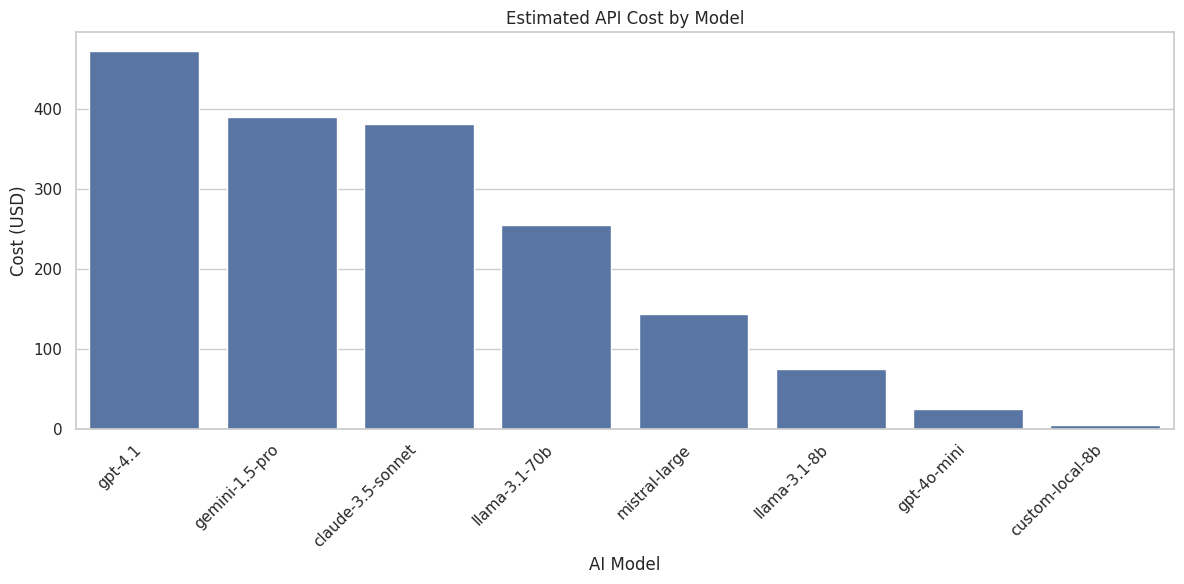

In [26]:
plt.figure(figsize=(12, 6))
sns.barplot(data=cost_by_model, x="model_name", y="Total_Cost")

plt.title("Estimated API Cost by Model")
plt.xlabel("AI Model")
plt.ylabel("Cost (USD)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [27]:
cost_by_provider = (
    eda_df.groupby("model_provider")
    .agg(
        Total_Cost=("cost_usd", "sum"),
        Total_Tokens=("total_tokens", "sum"),
        Total_Requests=("interaction_id", "count")
    )
    .reset_index()
    .sort_values("Total_Cost", ascending=False)
)

display(cost_by_provider)

,model_provider,Total_Cost,Total_Tokens,Total_Requests
5,openai,497.87672,2447174,2247
1,google,389.94144,1218567,1114
0,anthropic,381.52256,1192258,1085
3,meta,330.36620,2529479,2306
4,mistral,143.44392,1195366,1090
2,local,5.03928,1259629,1158


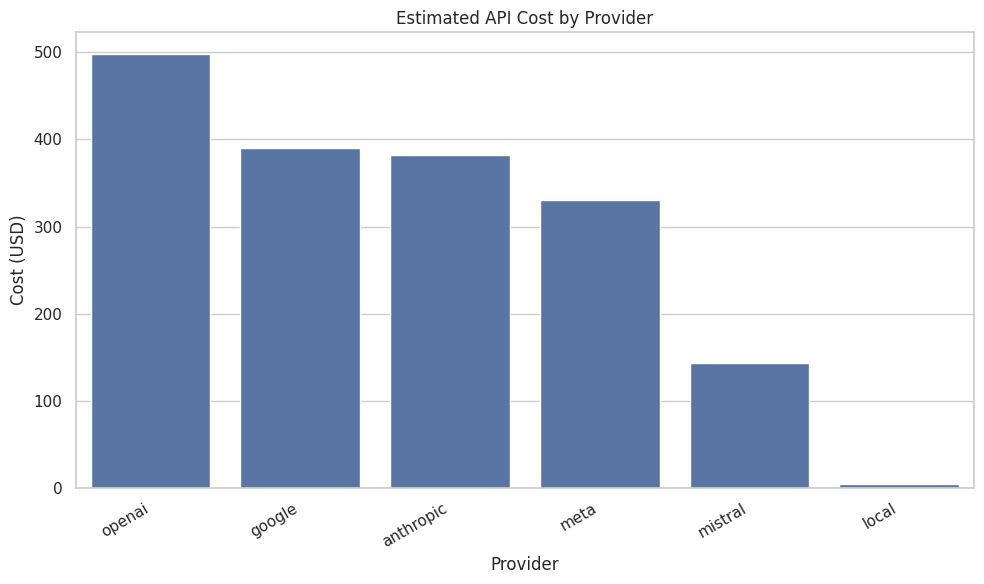

In [28]:
plt.figure(figsize=(10, 6))
sns.barplot(data=cost_by_provider, x="model_provider", y="Total_Cost")

plt.title("Estimated API Cost by Provider")
plt.xlabel("Provider")
plt.ylabel("Cost (USD)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [29]:
usecase_analysis = (
    eda_df.groupby("use_case")
    .agg(
        Total_Requests=("interaction_id", "count"),
        Total_Tokens=("total_tokens", "sum"),
        Total_Cost=("cost_usd", "sum"),
        Average_Latency=("latency_ms", "mean")
    )
    .reset_index()
    .sort_values("Total_Requests", ascending=False)
)

display(usecase_analysis)

,use_case,Total_Requests,Total_Tokens,Total_Cost,Average_Latency
3,customer_support,2723,2996979,533.31460,1210.434815
1,coding_assistant,1681,1871808,335.88860,1215.016062
4,data_analysis,1454,1574444,278.71732,1249.692572
2,content_writing,1441,1551684,268.94556,1201.165857
0,brainstorming,909,993220,176.60692,1217.328933
5,internal_qa,792,854338,154.71712,1192.277778


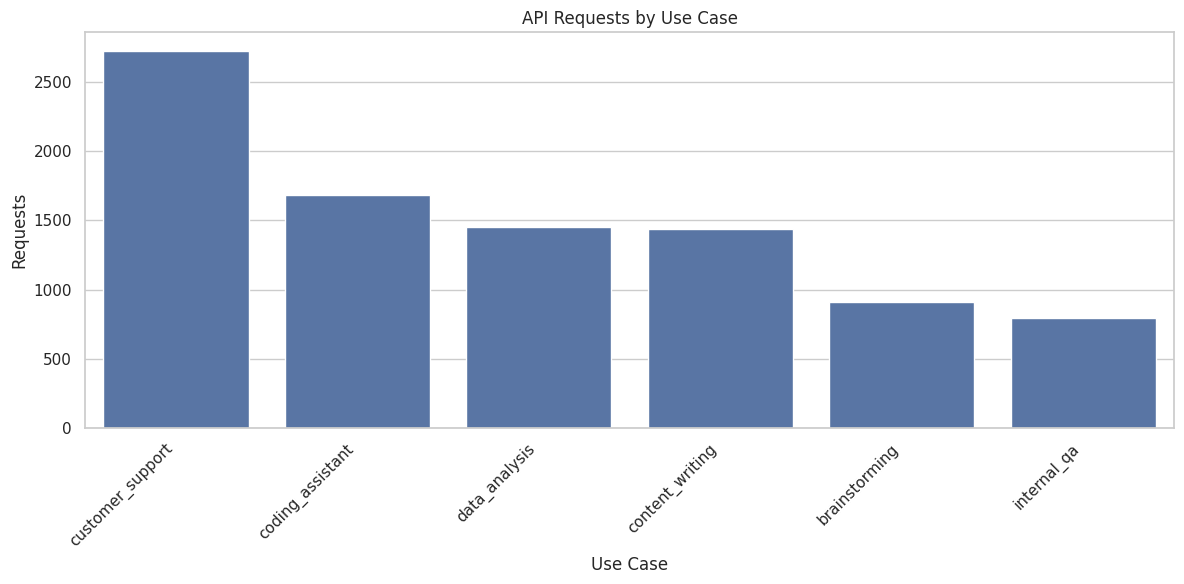

In [30]:
plt.figure(figsize=(12, 6))
sns.barplot(data=usecase_analysis, x="use_case", y="Total_Requests")

plt.title("API Requests by Use Case")
plt.xlabel("Use Case")
plt.ylabel("Requests")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [31]:
display(eda_df["latency_ms"].describe())

,latency_ms
count,9000.000000
mean,1215.247222
std,572.432030
min,156.000000
25%,812.000000
50%,1098.000000
75%,1484.000000
max,5622.000000


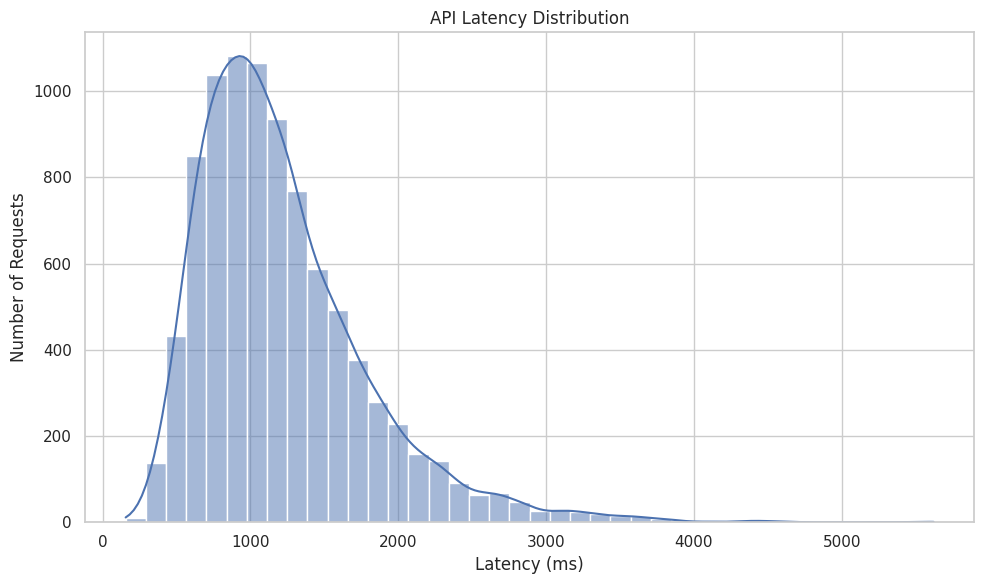

In [32]:
plt.figure(figsize=(10, 6))
sns.histplot(data=eda_df, x="latency_ms", bins=40, kde=True)

plt.title("API Latency Distribution")
plt.xlabel("Latency (ms)")
plt.ylabel("Number of Requests")
plt.tight_layout()
plt.show()

,model_name,latency_ms
1,custom-local-8b,1245.862694
0,claude-3.5-sonnet,1242.034101
3,gpt-4.1,1221.167126
6,llama-3.1-8b,1220.916376
7,mistral-large,1204.374312
4,gpt-4o-mini,1204.274611
5,llama-3.1-70b,1192.372193
2,gemini-1.5-pro,1191.526930


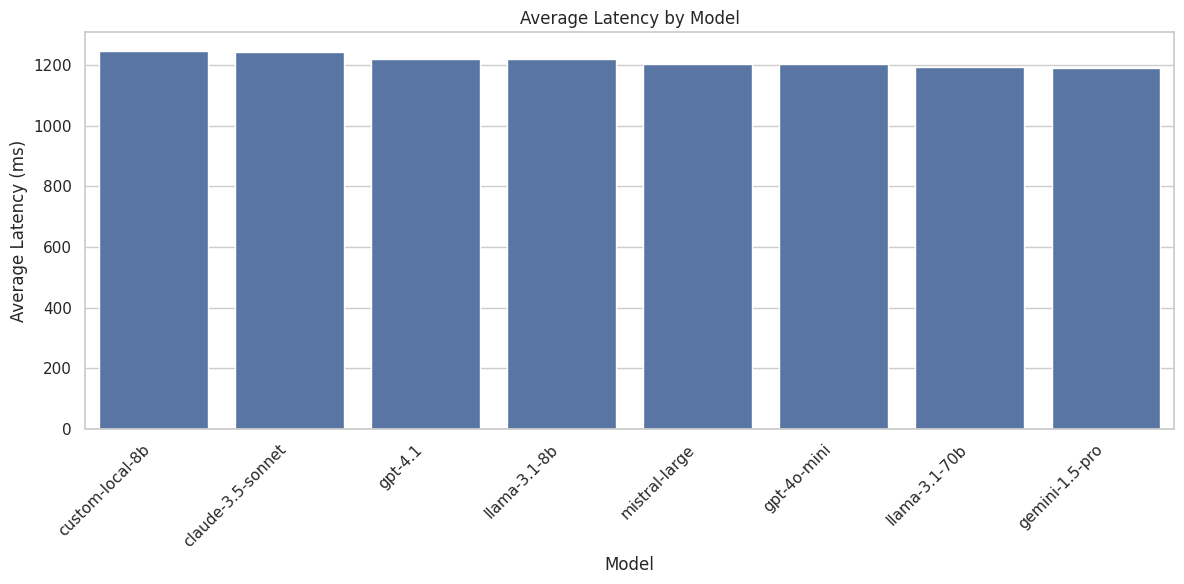

In [33]:
latency_by_model = (
    eda_df.groupby("model_name")["latency_ms"]
    .mean()
    .reset_index()
    .sort_values("latency_ms", ascending=False)
)

display(latency_by_model)

plt.figure(figsize=(12, 6))
sns.barplot(data=latency_by_model, x="model_name", y="latency_ms")

plt.title("Average Latency by Model")
plt.xlabel("Model")
plt.ylabel("Average Latency (ms)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [34]:
failure_by_model = (
    eda_df.groupby("model_name")
    .agg(
        Total_Requests=("interaction_id", "count"),
        Failed_Requests=("is_failure", "sum")
    )
    .reset_index()
)

failure_by_model["Failure_Rate_Percentage"] = (
    failure_by_model["Failed_Requests"]
    / failure_by_model["Total_Requests"]
) * 100

failure_by_model = failure_by_model.sort_values(
    "Failure_Rate_Percentage",
    ascending=False
)

display(failure_by_model)

,model_name,Total_Requests,Failed_Requests,Failure_Rate_Percentage
1,custom-local-8b,1158,356,30.742660
0,claude-3.5-sonnet,1085,321,29.585253
5,llama-3.1-70b,1158,329,28.411054
2,gemini-1.5-pro,1114,316,28.366248
4,gpt-4o-mini,1158,328,28.324698
7,mistral-large,1090,305,27.981651
3,gpt-4.1,1089,295,27.089073
6,llama-3.1-8b,1148,307,26.742160


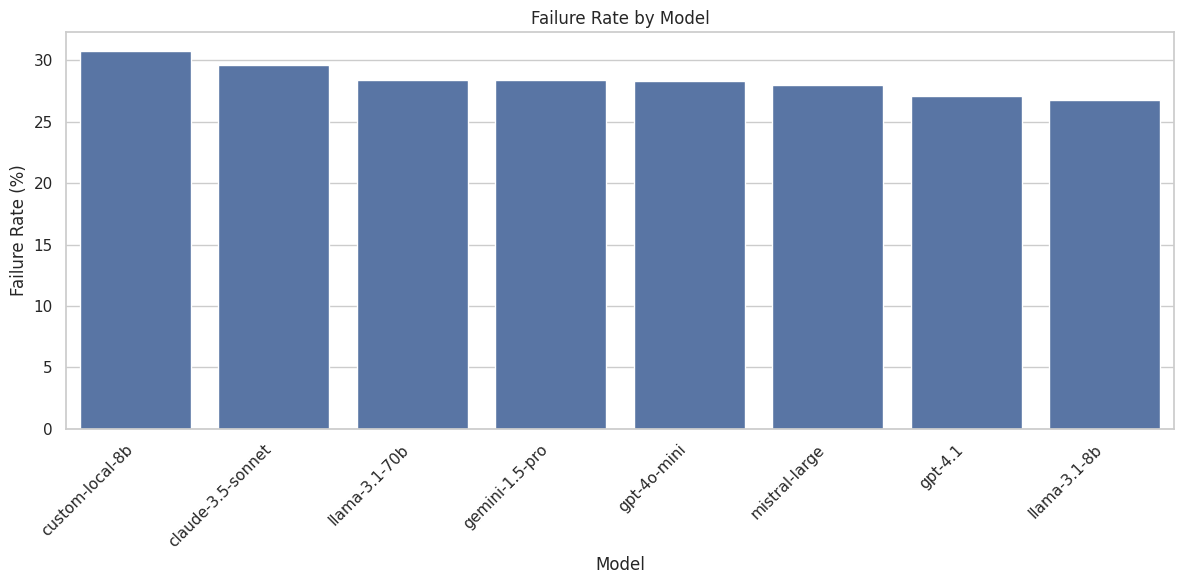

In [35]:
plt.figure(figsize=(12, 6))
sns.barplot(
    data=failure_by_model,
    x="model_name",
    y="Failure_Rate_Percentage"
)

plt.title("Failure Rate by Model")
plt.xlabel("Model")
plt.ylabel("Failure Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [36]:
failure_types = (
    eda_df[eda_df["is_failure"] == True]["failure_type"]
    .value_counts()
    .reset_index()
)

failure_types.columns = ["Failure_Type", "Count"]
display(failure_types)

,Failure_Type,Count
0,hallucination,744
1,formatting_error,569
2,tool_error,445
3,safety_block,406
4,latency_timeout,225
5,toxicity,168


,hour_of_day_utc,Total_Requests
0,0,259
1,1,267
2,2,295
3,3,290
4,4,231
5,5,137
6,6,226
7,7,441
8,8,605
9,9,666


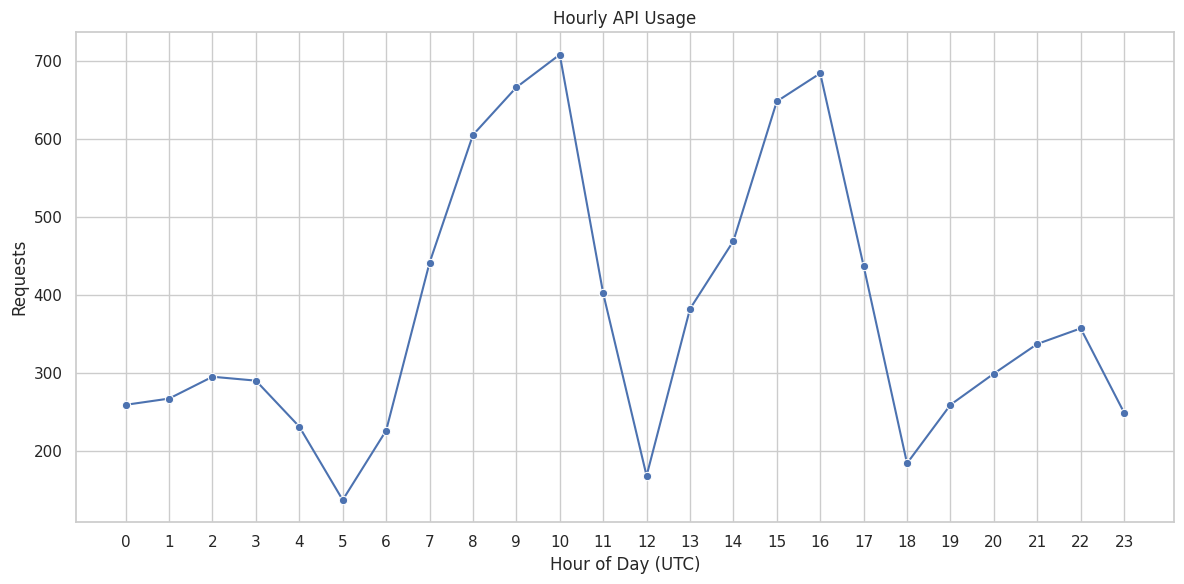

In [37]:
hourly_usage = (
    eda_df.groupby("hour_of_day_utc")
    .size()
    .reset_index(name="Total_Requests")
)

display(hourly_usage)

plt.figure(figsize=(12, 6))
sns.lineplot(
    data=hourly_usage,
    x="hour_of_day_utc",
    y="Total_Requests",
    marker="o"
)

plt.title("Hourly API Usage")
plt.xlabel("Hour of Day (UTC)")
plt.ylabel("Requests")
plt.xticks(range(24))
plt.tight_layout()
plt.show()

,date,Total_Requests,Total_Tokens,Total_Cost
0,2025-02-01,26,30440,4.76976
1,2025-02-02,45,44330,8.46212
2,2025-02-03,154,181613,30.95916
3,2025-02-04,164,166461,27.86956
4,2025-02-05,112,125145,19.95100


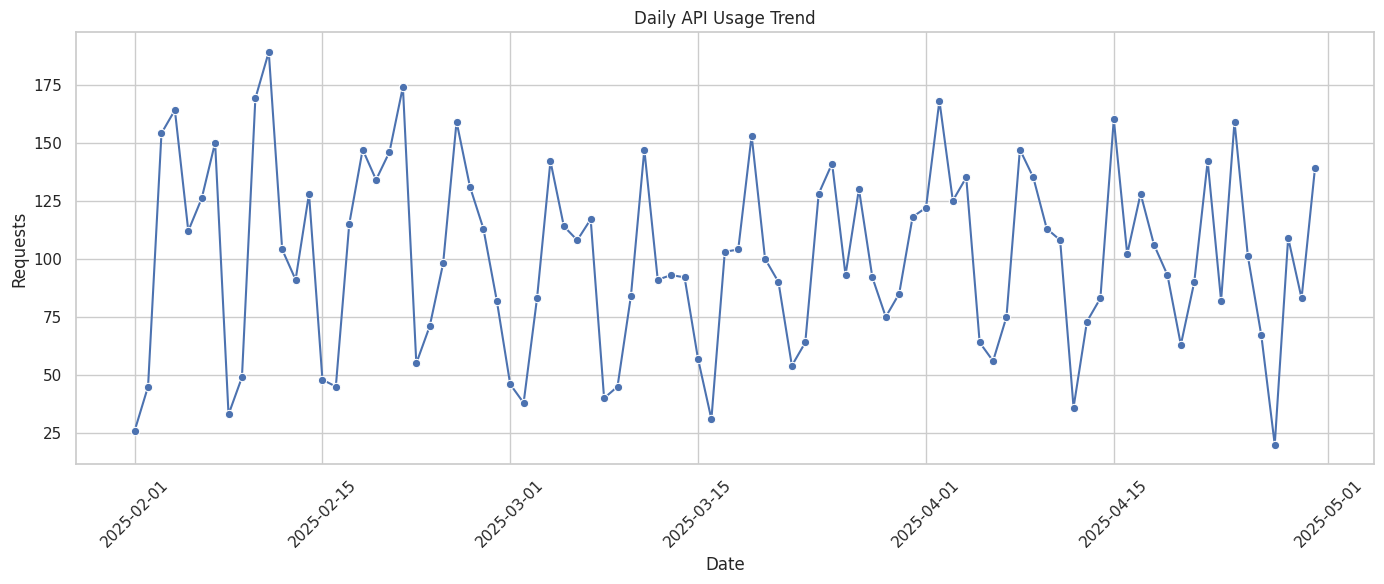

In [38]:
daily_usage = (
    eda_df.groupby("date")
    .agg(
        Total_Requests=("interaction_id", "count"),
        Total_Tokens=("total_tokens", "sum"),
        Total_Cost=("cost_usd", "sum")
    )
    .reset_index()
)

daily_usage["date"] = pd.to_datetime(daily_usage["date"])

display(daily_usage.head())

plt.figure(figsize=(14, 6))
sns.lineplot(
    data=daily_usage,
    x="date",
    y="Total_Requests",
    marker="o"
)

plt.title("Daily API Usage Trend")
plt.xlabel("Date")
plt.ylabel("Requests")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [39]:
tier_analysis = (
    eda_df.groupby("account_tier")
    .agg(
        Total_Requests=("interaction_id", "count"),
        Total_Tokens=("total_tokens", "sum"),
        Total_Cost=("cost_usd", "sum"),
        Unique_Users=("user_id", "nunique")
    )
    .reset_index()
    .sort_values("Total_Requests", ascending=False)
)

display(tier_analysis)

,account_tier,Total_Requests,Total_Tokens,Total_Cost,Unique_Users
1,free,5007,4751058,853.75548,240
2,pro,2532,3168714,565.99132,133
0,enterprise,1461,1922701,328.44332,65


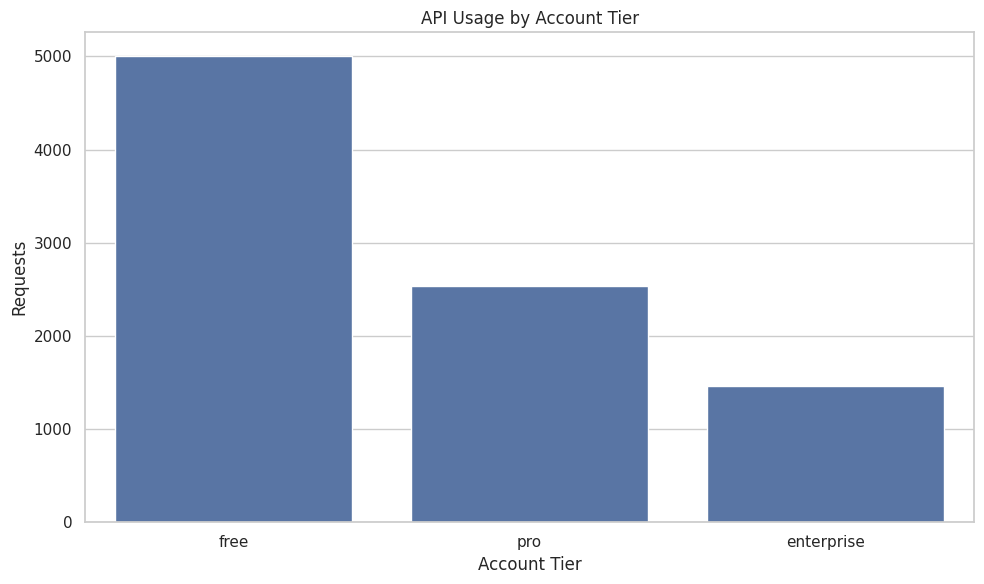

In [40]:
plt.figure(figsize=(10, 6))
sns.barplot(data=tier_analysis, x="account_tier", y="Total_Requests")

plt.title("API Usage by Account Tier")
plt.xlabel("Account Tier")
plt.ylabel("Requests")
plt.tight_layout()
plt.show()

In [41]:
quality_by_model = (
    eda_df.groupby("model_name")
    .agg(
        Average_Quality=("response_quality_score", "mean"),
        Average_Feedback=("user_feedback_score", "mean"),
        Feedback_Records=("user_feedback_score", "count")
    )
    .reset_index()
)

display(quality_by_model)

,model_name,Average_Quality,Average_Feedback,Feedback_Records
0,claude-3.5-sonnet,0.719975,0.593640,566
1,custom-local-8b,0.716054,0.549593,615
2,gemini-1.5-pro,0.724875,0.620232,603
3,gpt-4.1,0.725411,0.683502,594
4,gpt-4o-mini,0.722962,0.580952,630
5,llama-3.1-70b,0.723331,0.604466,627
6,llama-3.1-8b,0.731141,0.657813,640
7,mistral-large,0.726977,0.540496,605


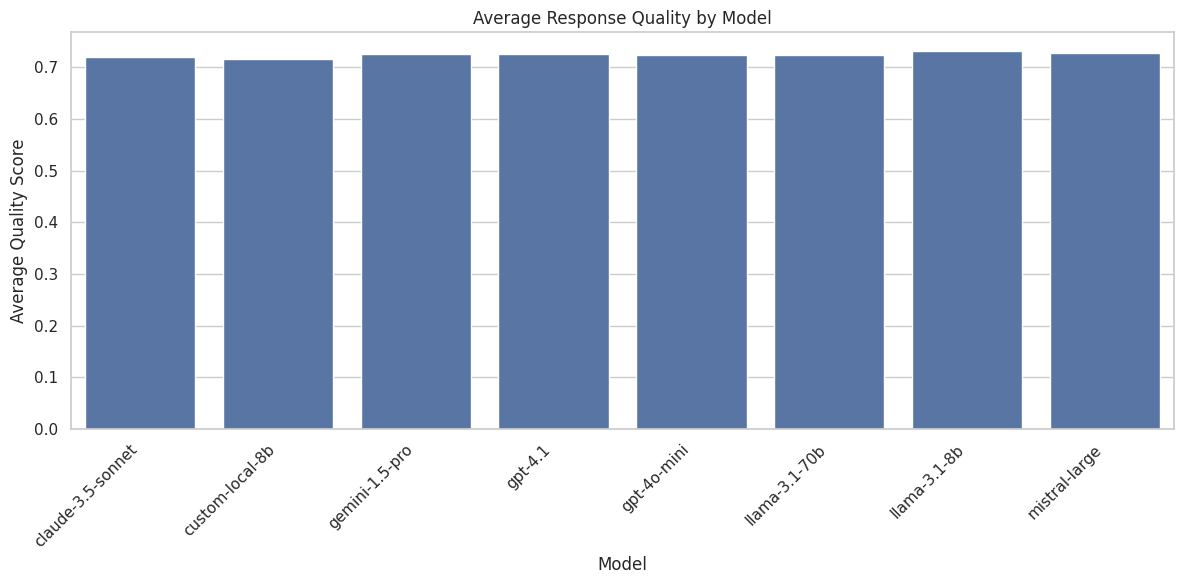

In [42]:
plt.figure(figsize=(12, 6))
sns.barplot(
    data=quality_by_model,
    x="model_name",
    y="Average_Quality"
)

plt.title("Average Response Quality by Model")
plt.xlabel("Model")
plt.ylabel("Average Quality Score")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [43]:
correlation_columns = [
    "prompt_tokens",
    "completion_tokens",
    "total_tokens",
    "cost_usd",
    "latency_ms",
    "tokens_per_second",
    "response_quality_score"
]

correlation_matrix = eda_df[correlation_columns].corr()

display(correlation_matrix)

,prompt_tokens,completion_tokens,total_tokens,cost_usd,latency_ms,tokens_per_second,response_quality_score
prompt_tokens,1.000000,0.066420,0.878712,0.403992,-0.017045,0.594936,0.058530
completion_tokens,0.066420,1.000000,0.534663,0.241504,0.015535,0.333480,0.019813
total_tokens,0.878712,0.534663,1.000000,0.457693,-0.007004,0.663412,0.059050
cost_usd,0.403992,0.241504,0.457693,1.000000,-0.007450,0.309661,0.027044
latency_ms,-0.017045,0.015535,-0.007004,-0.007450,1.000000,-0.565139,0.003293
tokens_per_second,0.594936,0.333480,0.663412,0.309661,-0.565139,1.000000,0.045464
response_quality_score,0.058530,0.019813,0.059050,0.027044,0.003293,0.045464,1.000000


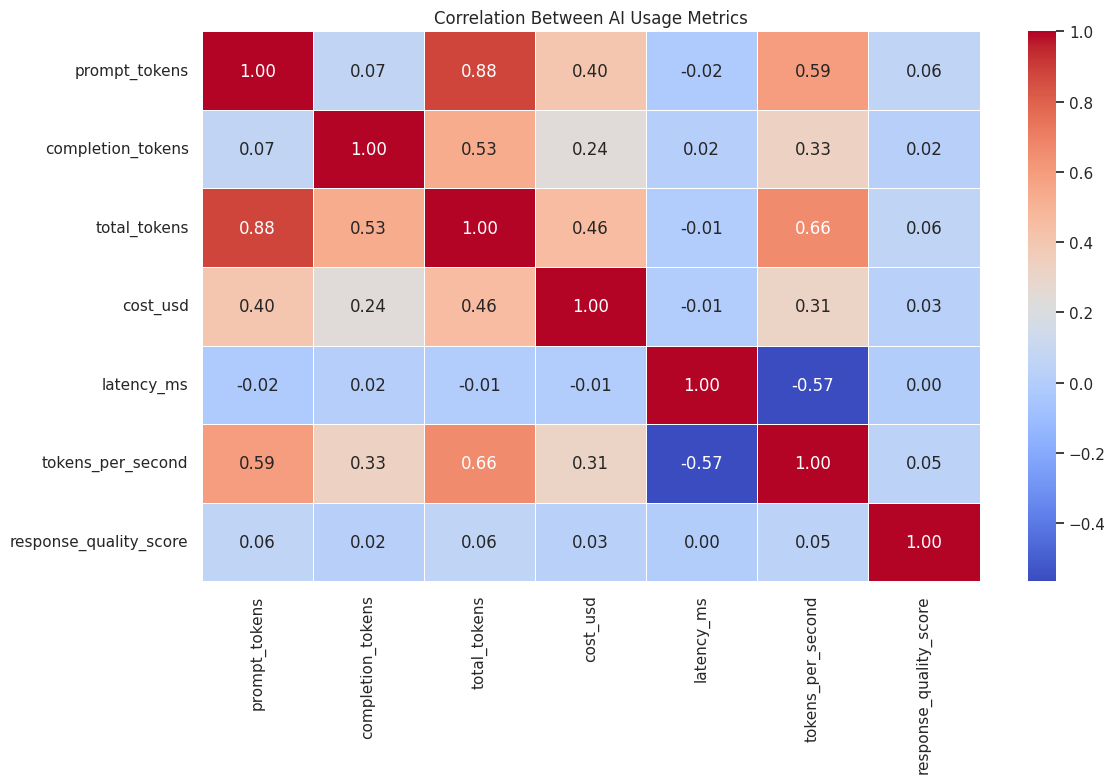

In [44]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between AI Usage Metrics")
plt.tight_layout()
plt.show()

In [45]:
EDA_PATH = "/content/drive/MyDrive/Token-Analytics/reports/eda"

os.makedirs(EDA_PATH, exist_ok=True)

eda_outputs = {
    "overall_kpi_summary.csv": kpi_summary,
    "model_usage_analysis.csv": model_usage,
    "token_consumption_analysis.csv": token_analysis,
    "cost_by_model.csv": cost_by_model,
    "cost_by_provider.csv": cost_by_provider,
    "usecase_analysis.csv": usecase_analysis,
    "failure_analysis.csv": failure_by_model,
    "daily_usage_analysis.csv": daily_usage,
    "account_tier_analysis.csv": tier_analysis,
    "response_quality_analysis.csv": quality_by_model
}

for filename, table in eda_outputs.items():
    table.to_csv(os.path.join(EDA_PATH, filename), index=False)

print("All EDA results exported successfully!")
print("Saved to:", EDA_PATH)

All EDA results exported successfully!
Saved to: /content/drive/MyDrive/Token-Analytics/reports/eda


In [46]:
!pip install -q sqlalchemy psycopg2-binary

In [47]:
from sqlalchemy import create_engine, text
from google.colab import userdata

print("PostgreSQL libraries imported successfully!")

PostgreSQL libraries imported successfully!


In [48]:
from sqlalchemy import create_engine, text
from google.colab import userdata

# Get Neon PostgreSQL connection string
DATABASE_URL = userdata.get("NEON_DATABASE_URL")

# Explicitly use psycopg2 driver
DATABASE_URL = DATABASE_URL.replace(
    "postgresql://",
    "postgresql+psycopg2://",
    1
)

# Create database engine
engine = create_engine(
    DATABASE_URL,
    pool_pre_ping=True,
    connect_args={"sslmode": "require"}
)

# Test connection
with engine.connect() as connection:
    result = connection.execute(text("SELECT version();"))
    print("PostgreSQL connected successfully!")
    print(result.fetchone()[0])

PostgreSQL connected successfully!
PostgreSQL 18.6 (ac70818) on aarch64-unknown-linux-gnu, compiled by gcc (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0, 64-bit


In [49]:
with engine.connect() as connection:

    result = connection.execute(
        text("SELECT version();")
    )

    database_version = result.fetchone()[0]

    print("PostgreSQL connection successful!")
    print(database_version)

PostgreSQL connection successful!
PostgreSQL 18.6 (ac70818) on aarch64-unknown-linux-gnu, compiled by gcc (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0, 64-bit


In [50]:
# Create a separate copy
df_sql = df_clean.copy()

# Convert timestamp columns
df_sql["timestamp_utc"] = pd.to_datetime(
    df_sql["timestamp_utc"],
    errors="coerce",
    utc=True
)

df_sql["date_utc"] = pd.to_datetime(
    df_sql["date_utc"],
    errors="coerce"
)

# Display dataset information
print("Dataset prepared successfully!")
print("Total records:", len(df_sql))
print("Total columns:", len(df_sql.columns))

display(df_sql.head())

Dataset prepared successfully!
Total records: 9000
Total columns: 63


,interaction_id,session_id,user_id,timestamp_utc,split,channel,use_case,country_code,region,account_tier,segment,instruction_template,model_provider,model_name,temperature,top_p,max_tokens,prompt_tokens,completion_tokens,total_tokens,latency_ms,cost_usd,response_quality_score,is_failure,failure_type,hallucination_flag,toxicity_flag,safety_block_flag,formatting_error_flag,tool_error_flag,latency_timeout_flag,tool_calls_count,tools_used,user_feedback_score,user_feedback_label,user_reported_issue,retry_index,repair_strategy,final_resolution_state,business_impact_tag,request_text,response_text_snippet,tokens_per_second,date_utc,hour_of_day_utc,day_of_week,is_weekend,is_peak_hour,prompt_to_completion_ratio,request_text_template,instruction_text,user_feedback_observed,prompt_id,response_text_snippet_len_chars,response_text_snippet_is_truncated,calculated_total_tokens,token_mismatch,year,month,month_name,hour,input_token_percentage,output_token_percentage
0,INT000001,S01207,U00013,2025-03-25 11:14:35+00:00,train,web_app,coding_assistant,BR,AMER,pro,enterprise_team,creative_writer,meta,llama-3.1-70b,0.257,0.898,768,186,422,608,615,0.12160,0.846,False,none,False,False,False,False,False,False,0,none,2.0,positive,False,0,none,auto_resolved,medium,Can you help me debug this? I'm getting a Pyth...,Let's turn this into a reliable workflow. Goal...,988.617886,2025-03-25,11,1,False,True,0.4408,I'm getting a Python error: `NullPointerExcept...,You are a senior software engineer helping use...,True,83c939e9b891e505ac06548e158556e919317a64,216,True,608,False,2025,3,March,11,30.592105,69.407895
1,INT000002,S01119,U00017,2025-02-23 04:08:56+00:00,val,mobile_app,customer_support,IN,APAC,free,individual,general_assistant,anthropic,claude-3.5-sonnet,0.806,0.890,768,701,410,1111,1194,0.35552,0.352,True,formatting_error,False,False,False,True,False,False,0,none,NaN,no_feedback,False,0,enable_tools,escalated_to_human,high,I'm stuck on this and need some guidance: Our ...,Let's break this down into actionable steps. S...,930.485762,2025-02-23,4,6,True,False,1.7098,Our customer is getting an error when trying t...,You are a helpful customer support assistant f...,False,a52fb80193c7c0769c0836852624f4b025a04d2a,207,True,1111,False,2025,2,February,4,63.096310,36.903690
2,INT000003,S00653,U00155,2025-02-25 17:31:08+00:00,train,web_app,brainstorming,GB,EMEA,free,team,code_assistant_secure,google,gemini-1.5-pro,0.412,0.898,1024,425,131,556,1196,0.17792,0.543,True,safety_block,False,False,True,False,False,False,0,none,NaN,no_feedback,False,0,manual_post_edit,abandoned,low,Context for you: Brainstorm taglines for a pro...,This is a common pattern; the fix is straightf...,464.882943,2025-02-25,17,1,False,True,3.2443,Brainstorm taglines for a productivity app tha...,You are a creative assistant helping users exp...,False,9886b059d7fa547dc6fd91d4a5c80abdb317022d,223,True,556,False,2025,2,February,17,76.438849,23.561151
3,INT000004,S00103,U00263,2025-03-14 17:42:16+00:00,train,web_app,content_writing,AU,APAC,free,team,creative_writer,google,gemini-1.5-pro,0.637,0.822,1024,1173,545,1718,1266,0.54976,0.888,False,none,False,False,False,False,False,False,0,none,NaN,no_feedback,False,0,none,auto_resolved,high,I'm working on something and need help: Draft ...,Here's what I'd implement in production. Goal:...,1357.030016,2025-03-14,17,4,False,True,2.1523,Draft a friendly email announcing a small pric...,You are a writing assistant helping users craf...,False,469eb15f8b08d9b4130e14a6c3888f14e335a854,236,True,1718,False,2025,3,March,17,68.277066,31.722934
4,INT000005,S01553,U00118,2025-02-24 00:39:04+00:00,train,api,data_analysis,IN,APAC,enterprise,individual,support_strict,meta,llama-3.1-8b,0.414,0.949,512,65,431,496,833,0.02976,0.755,False,none,False,False,False,False,False,False,2,email_send|knowledge_lookup,0.0,neutral,False,0,none,auto_resolved,low,Quick question: I have a CSV with user session...,Let's turn this into a reliable workflow. Goal...,595.438175,2025-02-24,0,

In [51]:
# Check duplicate interaction IDs
duplicate_ids = df_sql["interaction_id"].duplicated().sum()

# Check missing interaction IDs
missing_ids = df_sql["interaction_id"].isna().sum()

# Check total token mismatches
token_mismatches = (
    df_sql["total_tokens"] !=
    (df_sql["prompt_tokens"] + df_sql["completion_tokens"])
).sum()

print("Duplicate interaction IDs:", duplicate_ids)
print("Missing interaction IDs:", missing_ids)
print("Token mismatches:", token_mismatches)

Duplicate interaction IDs: 0
Missing interaction IDs: 0
Token mismatches: 0


In [52]:
df_sql.to_sql(
    name="stg_interactions",
    con=engine,
    if_exists="replace",
    index=False,
    chunksize=1000,
    method="multi"
)

print("Dataset uploaded successfully!")
print("PostgreSQL table: stg_interactions")

Dataset uploaded successfully!
PostgreSQL table: stg_interactions


In [53]:
with engine.connect() as connection:

    result = connection.execute(
        text("""
            SELECT COUNT(*)
            FROM stg_interactions;
        """)
    )

    database_records = result.scalar()

print("Python records:", len(df_sql))
print("PostgreSQL records:", database_records)

if database_records == len(df_sql):
    print("SUCCESS: All records uploaded!")
else:
    print("WARNING: Record counts do not match!")

Python records: 9000
PostgreSQL records: 9000
SUCCESS: All records uploaded!


In [54]:
query = """
SELECT
    interaction_id,
    user_id,
    model_provider,
    model_name,
    prompt_tokens,
    completion_tokens,
    total_tokens,
    cost_usd,
    latency_ms
FROM stg_interactions
LIMIT 10;
"""

with engine.connect() as connection:
    preview_df = pd.read_sql_query(
        text(query),
        connection
    )

display(preview_df)

,interaction_id,user_id,model_provider,model_name,prompt_tokens,completion_tokens,total_tokens,cost_usd,latency_ms
0,INT000001,U00013,meta,llama-3.1-70b,186,422,608,0.12160,615
1,INT000002,U00017,anthropic,claude-3.5-sonnet,701,410,1111,0.35552,1194
2,INT000003,U00155,google,gemini-1.5-pro,425,131,556,0.17792,1196
3,INT000004,U00263,google,gemini-1.5-pro,1173,545,1718,0.54976,1266
4,INT000005,U00118,meta,llama-3.1-8b,65,431,496,0.02976,833
5,INT000006,U00038,meta,llama-3.1-70b,255,77,332,0.06640,1517
6,INT000007,U00216,local,custom-local-8b,528,949,1477,0.00592,2135
7,INT000008,U00160,meta,llama-3.1-70b,1248,65,1313,0.26260,808
8,INT000009,U00414,meta,llama-3.1-8b,634,217,851,0.05108,1652
9,INT000010,U00017,google,gemini-1.5-pro,965,285,1250,0.40000,3052


In [55]:
query = """
SELECT
    column_name,
    data_type
FROM information_schema.columns
WHERE table_name = 'stg_interactions'
ORDER BY ordinal_position;
"""

with engine.connect() as connection:
    schema_df = pd.read_sql_query(
        text(query),
        connection
    )

display(schema_df)

,column_name,data_type
0,interaction_id,text
1,session_id,text
2,user_id,text
3,timestamp_utc,timestamp with time zone
4,split,text
...,...,...
58,month,integer
59,month_name,text
60,hour,integer
61,input_token_percentage,double precision


In [56]:
index_queries = [
    """
    CREATE INDEX IF NOT EXISTS idx_interaction_timestamp
    ON stg_interactions(timestamp_utc);
    """,

    """
    CREATE INDEX IF NOT EXISTS idx_interaction_model
    ON stg_interactions(model_name);
    """,

    """
    CREATE INDEX IF NOT EXISTS idx_interaction_user
    ON stg_interactions(user_id);
    """,

    """
    CREATE INDEX IF NOT EXISTS idx_interaction_provider
    ON stg_interactions(model_provider);
    """,

    """
    CREATE INDEX IF NOT EXISTS idx_interaction_usecase
    ON stg_interactions(use_case);
    """
]

with engine.begin() as connection:

    for query in index_queries:
        connection.execute(text(query))

print("All PostgreSQL indexes created successfully!")

All PostgreSQL indexes created successfully!


In [57]:
from sqlalchemy import text
import pandas as pd

def run_sql(query):
    with engine.connect() as connection:
        result = pd.read_sql_query(
            text(query),
            connection
        )
    return result

print("SQL function ready!")

SQL function ready!


In [58]:
query = """
SELECT
    COUNT(*) AS total_requests,
    COUNT(DISTINCT user_id) AS unique_users,
    COUNT(DISTINCT model_name) AS models_used,
    SUM(prompt_tokens) AS total_prompt_tokens,
    SUM(completion_tokens) AS total_completion_tokens,
    SUM(total_tokens) AS total_tokens,
    ROUND(SUM(cost_usd)::numeric, 4) AS total_estimated_cost_usd,
    ROUND(AVG(latency_ms)::numeric, 2) AS average_latency_ms,
    SUM(CASE WHEN is_failure THEN 1 ELSE 0 END) AS failed_requests,
    ROUND(
        100.0 * SUM(CASE WHEN is_failure THEN 1 ELSE 0 END)
        / NULLIF(COUNT(*), 0),
        2
    ) AS failure_rate_percentage
FROM stg_interactions;
"""

kpi_sql = run_sql(query)
display(kpi_sql)

,total_requests,unique_users,models_used,total_prompt_tokens,total_completion_tokens,total_tokens,total_estimated_cost_usd,average_latency_ms,failed_requests,failure_rate_percentage
0,9000,438,8,6328824.0,3513649.0,9842473.0,1748.1901,1215.25,2557,28.41


In [59]:
query = """
SELECT
    model_name,
    COUNT(*) AS total_requests,
    SUM(total_tokens) AS total_tokens,
    ROUND(SUM(cost_usd)::numeric, 4) AS total_cost_usd,
    ROUND(AVG(latency_ms)::numeric, 2) AS average_latency_ms
FROM stg_interactions
GROUP BY model_name
ORDER BY total_requests DESC;
"""

model_sql = run_sql(query)
display(model_sql)

,model_name,total_requests,total_tokens,total_cost_usd,average_latency_ms
0,llama-3.1-70b,1158,1275683.0,255.1366,1192.37
1,gpt-4o-mini,1158,1265778.0,25.3183,1204.27
2,custom-local-8b,1158,1259629.0,5.0393,1245.86
3,llama-3.1-8b,1148,1253796.0,75.2296,1220.92
4,gemini-1.5-pro,1114,1218567.0,389.9414,1191.53
5,mistral-large,1090,1195366.0,143.4439,1204.37
6,gpt-4.1,1089,1181396.0,472.5584,1221.17
7,claude-3.5-sonnet,1085,1192258.0,381.5226,1242.03


In [60]:
query = """
SELECT
    model_name,
    SUM(prompt_tokens) AS prompt_tokens,
    SUM(completion_tokens) AS completion_tokens,
    SUM(total_tokens) AS total_tokens,
    ROUND(
        100.0 * SUM(prompt_tokens) /
        NULLIF(SUM(total_tokens), 0),
        2
    ) AS prompt_percentage,
    ROUND(
        100.0 * SUM(completion_tokens) /
        NULLIF(SUM(total_tokens), 0),
        2
    ) AS completion_percentage
FROM stg_interactions
GROUP BY model_name
ORDER BY total_tokens DESC;
"""

token_sql = run_sql(query)
display(token_sql)

,model_name,prompt_tokens,completion_tokens,total_tokens,prompt_percentage,completion_percentage
0,llama-3.1-70b,816663.0,459020.0,1275683.0,64.02,35.98
1,gpt-4o-mini,810075.0,455703.0,1265778.0,64.00,36.00
2,custom-local-8b,813829.0,445800.0,1259629.0,64.61,35.39
3,llama-3.1-8b,802393.0,451403.0,1253796.0,64.00,36.00
4,gemini-1.5-pro,791347.0,427220.0,1218567.0,64.94,35.06
5,mistral-large,767753.0,427613.0,1195366.0,64.23,35.77
6,claude-3.5-sonnet,772609.0,419649.0,1192258.0,64.80,35.20
7,gpt-4.1,754155.0,427241.0,1181396.0,63.84,36.16


In [61]:
query = """
SELECT
    model_provider,
    COUNT(*) AS total_requests,
    SUM(total_tokens) AS total_tokens,
    ROUND(SUM(cost_usd)::numeric, 4) AS total_cost_usd,
    ROUND(AVG(cost_usd)::numeric, 6) AS average_cost_per_request
FROM stg_interactions
GROUP BY model_provider
ORDER BY total_cost_usd DESC;
"""

provider_sql = run_sql(query)
display(provider_sql)

,model_provider,total_requests,total_tokens,total_cost_usd,average_cost_per_request
0,openai,2247,2447174.0,497.8767,0.221574
1,google,1114,1218567.0,389.9414,0.350037
2,anthropic,1085,1192258.0,381.5226,0.351634
3,meta,2306,2529479.0,330.3662,0.143264
4,mistral,1090,1195366.0,143.4439,0.131600
5,local,1158,1259629.0,5.0393,0.004352


In [62]:
query = """
SELECT
    use_case,
    COUNT(*) AS total_requests,
    SUM(total_tokens) AS total_tokens,
    ROUND(SUM(cost_usd)::numeric, 4) AS total_cost_usd,
    ROUND(AVG(latency_ms)::numeric, 2) AS average_latency_ms
FROM stg_interactions
GROUP BY use_case
ORDER BY total_cost_usd DESC;
"""

usecase_sql = run_sql(query)
display(usecase_sql)

,use_case,total_requests,total_tokens,total_cost_usd,average_latency_ms
0,customer_support,2723,2996979.0,533.3146,1210.43
1,coding_assistant,1681,1871808.0,335.8886,1215.02
2,data_analysis,1454,1574444.0,278.7173,1249.69
3,content_writing,1441,1551684.0,268.9456,1201.17
4,brainstorming,909,993220.0,176.6069,1217.33
5,internal_qa,792,854338.0,154.7171,1192.28


In [63]:
query = """
SELECT
    DATE(timestamp_utc) AS usage_date,
    COUNT(*) AS total_requests,
    SUM(prompt_tokens) AS prompt_tokens,
    SUM(completion_tokens) AS completion_tokens,
    SUM(total_tokens) AS total_tokens,
    ROUND(SUM(cost_usd)::numeric, 4) AS daily_cost_usd
FROM stg_interactions
GROUP BY DATE(timestamp_utc)
ORDER BY usage_date;
"""

daily_sql = run_sql(query)
display(daily_sql)

,usage_date,total_requests,prompt_tokens,completion_tokens,total_tokens,daily_cost_usd
0,2025-02-01,26,20713.0,9727.0,30440.0,4.7698
1,2025-02-02,45,26932.0,17398.0,44330.0,8.4621
2,2025-02-03,154,116421.0,65192.0,181613.0,30.9592
3,2025-02-04,164,103168.0,63293.0,166461.0,27.8696
4,2025-02-05,112,82301.0,42844.0,125145.0,19.9510
...,...,...,...,...,...,...
84,2025-04-26,67,54285.0,25318.0,79603.0,17.4632
85,2025-04-27,20,14051.0,7364.0,21415.0,3.2266
86,2025-04-28,109,76212.0,45522.0,121734.0,23.0066
87,2025-04-29,83,67806.0,34137.0,101943.0,14.8896


In [64]:
query = """
SELECT
    model_name,
    COUNT(*) AS total_requests,
    SUM(CASE WHEN is_failure THEN 1 ELSE 0 END) AS failed_requests,
    ROUND(
        100.0 * SUM(CASE WHEN is_failure THEN 1 ELSE 0 END)
        / NULLIF(COUNT(*), 0),
        2
    ) AS failure_rate_percentage
FROM stg_interactions
GROUP BY model_name
ORDER BY failure_rate_percentage DESC;
"""

failure_sql = run_sql(query)
display(failure_sql)

,model_name,total_requests,failed_requests,failure_rate_percentage
0,custom-local-8b,1158,356,30.74
1,claude-3.5-sonnet,1085,321,29.59
2,llama-3.1-70b,1158,329,28.41
3,gemini-1.5-pro,1114,316,28.37
4,gpt-4o-mini,1158,328,28.32
5,mistral-large,1090,305,27.98
6,gpt-4.1,1089,295,27.09
7,llama-3.1-8b,1148,307,26.74


In [65]:
query = """
SELECT
    failure_type,
    COUNT(*) AS failure_count
FROM stg_interactions
WHERE is_failure = TRUE
GROUP BY failure_type
ORDER BY failure_count DESC;
"""

failure_type_sql = run_sql(query)
display(failure_type_sql)

,failure_type,failure_count
0,hallucination,744
1,formatting_error,569
2,tool_error,445
3,safety_block,406
4,latency_timeout,225
5,toxicity,168


In [66]:
query = """
SELECT
    model_name,
    ROUND(AVG(latency_ms)::numeric, 2) AS average_latency_ms,
    MIN(latency_ms) AS minimum_latency_ms,
    MAX(latency_ms) AS maximum_latency_ms,
    ROUND(
        PERCENTILE_CONT(0.95)
        WITHIN GROUP (ORDER BY latency_ms)::numeric,
        2
    ) AS p95_latency_ms
FROM stg_interactions
GROUP BY model_name
ORDER BY average_latency_ms DESC;
"""

latency_sql = run_sql(query)
display(latency_sql)

,model_name,average_latency_ms,minimum_latency_ms,maximum_latency_ms,p95_latency_ms
0,custom-local-8b,1245.86,276,5516,2291.90
1,claude-3.5-sonnet,1242.03,225,4534,2482.60
2,gpt-4.1,1221.17,202,4086,2441.80
3,llama-3.1-8b,1220.92,321,4422,2340.15
4,mistral-large,1204.37,275,3844,2297.80
5,gpt-4o-mini,1204.27,281,4407,2263.95
6,llama-3.1-70b,1192.37,224,3857,2245.45
7,gemini-1.5-pro,1191.53,156,5622,2237.35


In [67]:
query = """
SELECT
    user_id,
    COUNT(*) AS total_requests,
    SUM(total_tokens) AS total_tokens,
    ROUND(SUM(cost_usd)::numeric, 4) AS total_cost_usd
FROM stg_interactions
GROUP BY user_id
ORDER BY total_tokens DESC
LIMIT 10;
"""

top_users_sql = run_sql(query)
display(top_users_sql)

,user_id,total_requests,total_tokens,total_cost_usd
0,U00335,48,61782.0,11.1711
1,U00116,39,58570.0,11.9940
2,U00306,44,56996.0,7.7964
3,U00399,46,56401.0,10.8373
4,U00214,37,55743.0,10.2772
5,U00013,45,55409.0,8.1820
6,U00209,46,55212.0,11.4926
7,U00289,43,54082.0,10.0326
8,U00163,44,53537.0,9.6336
9,U00061,41,53244.0,9.1045


In [68]:
query = """
SELECT
    account_tier,
    COUNT(*) AS total_requests,
    COUNT(DISTINCT user_id) AS unique_users,
    SUM(total_tokens) AS total_tokens,
    ROUND(SUM(cost_usd)::numeric, 4) AS total_cost_usd,
    ROUND(AVG(latency_ms)::numeric, 2) AS average_latency_ms
FROM stg_interactions
GROUP BY account_tier
ORDER BY total_cost_usd DESC;
"""

tier_sql = run_sql(query)
display(tier_sql)

,account_tier,total_requests,unique_users,total_tokens,total_cost_usd,average_latency_ms
0,free,5007,240,4751058.0,853.7555,1220.35
1,pro,2532,133,3168714.0,565.9913,1211.25
2,enterprise,1461,65,1922701.0,328.4433,1204.68


In [69]:
query = """
SELECT
    hour_of_day_utc,
    COUNT(*) AS total_requests,
    SUM(total_tokens) AS total_tokens,
    ROUND(SUM(cost_usd)::numeric, 4) AS total_cost_usd
FROM stg_interactions
GROUP BY hour_of_day_utc
ORDER BY hour_of_day_utc;
"""

hourly_sql = run_sql(query)
display(hourly_sql)

,hour_of_day_utc,total_requests,total_tokens,total_cost_usd
0,0,259,299445.0,59.0291
1,1,267,305956.0,54.8562
2,2,295,330852.0,54.7647
3,3,290,300160.0,51.3115
4,4,231,256049.0,44.3130
5,5,137,147829.0,26.9500
6,6,226,252677.0,47.0394
7,7,441,475042.0,82.8803
8,8,605,669678.0,123.1166
9,9,666,711042.0,131.9524


In [70]:
query = """
SELECT
    model_name,
    ROUND(AVG(response_quality_score)::numeric, 3)
        AS average_quality_score,
    ROUND(AVG(user_feedback_score)::numeric, 3)
        AS average_feedback_score,
    COUNT(user_feedback_score) AS feedback_records
FROM stg_interactions
GROUP BY model_name
ORDER BY average_quality_score DESC;
"""

quality_sql = run_sql(query)
display(quality_sql)

,model_name,average_quality_score,average_feedback_score,feedback_records
0,llama-3.1-8b,0.731,0.658,640
1,mistral-large,0.727,0.540,605
2,gpt-4.1,0.725,0.684,594
3,gemini-1.5-pro,0.725,0.620,603
4,gpt-4o-mini,0.723,0.581,630
5,llama-3.1-70b,0.723,0.604,627
6,claude-3.5-sonnet,0.720,0.594,566
7,custom-local-8b,0.716,0.550,615


In [71]:
query = """
SELECT
    interaction_id,
    model_name,
    model_provider,
    use_case,
    total_tokens,
    cost_usd,
    latency_ms
FROM stg_interactions
ORDER BY cost_usd DESC
LIMIT 20;
"""

expensive_requests_sql = run_sql(query)
display(expensive_requests_sql)

,interaction_id,model_name,model_provider,use_case,total_tokens,cost_usd,latency_ms
0,INT001841,gpt-4.1,openai,customer_support,2617,1.04680,1788
1,INT007338,gpt-4.1,openai,data_analysis,2563,1.02520,2035
2,INT000071,gpt-4.1,openai,content_writing,2560,1.02400,1099
3,INT006806,gpt-4.1,openai,customer_support,2547,1.01880,1400
4,INT005622,gpt-4.1,openai,customer_support,2480,0.99200,399
5,INT000220,gpt-4.1,openai,brainstorming,2470,0.98800,1253
6,INT005054,gpt-4.1,openai,internal_qa,2457,0.98280,1069
7,INT002454,gpt-4.1,openai,customer_support,2432,0.97280,787
8,INT000447,gpt-4.1,openai,customer_support,2359,0.94360,1134
9,INT005233,gpt-4.1,openai,customer_support,2327,0.93080,616


In [72]:
query = """
SELECT
    interaction_id,
    model_name,
    use_case,
    prompt_tokens,
    completion_tokens,
    total_tokens,
    cost_usd
FROM stg_interactions
ORDER BY total_tokens DESC
LIMIT 20;
"""

high_token_requests_sql = run_sql(query)
display(high_token_requests_sql)

,interaction_id,model_name,use_case,prompt_tokens,completion_tokens,total_tokens,cost_usd
0,INT000983,claude-3.5-sonnet,internal_qa,1712,1042,2754,0.88128
1,INT006047,mistral-large,customer_support,1818,926,2744,0.32928
2,INT000481,llama-3.1-70b,customer_support,1711,1024,2735,0.54700
3,INT001214,custom-local-8b,customer_support,1669,1023,2692,0.01076
4,INT007503,llama-3.1-8b,customer_support,1664,1024,2688,0.16128
5,INT004032,custom-local-8b,customer_support,1827,849,2676,0.01072
6,INT006800,claude-3.5-sonnet,content_writing,1742,931,2673,0.85536
7,INT005451,gpt-4o-mini,coding_assistant,1600,1034,2634,0.05268
8,INT001841,gpt-4.1,customer_support,1578,1039,2617,1.04680
9,INT005265,llama-3.1-8b,internal_qa,1841,768,2609,0.15656


In [73]:
query = """
SELECT
    model_name,
    COUNT(*) AS total_requests,
    SUM(CASE WHEN hallucination_flag THEN 1 ELSE 0 END)
        AS hallucination_count,
    SUM(CASE WHEN toxicity_flag THEN 1 ELSE 0 END)
        AS toxicity_count,
    SUM(CASE WHEN safety_block_flag THEN 1 ELSE 0 END)
        AS safety_block_count,
    SUM(CASE WHEN tool_error_flag THEN 1 ELSE 0 END)
        AS tool_error_count
FROM stg_interactions
GROUP BY model_name
ORDER BY total_requests DESC;
"""

reliability_sql = run_sql(query)
display(reliability_sql)

,model_name,total_requests,hallucination_count,toxicity_count,safety_block_count,tool_error_count
0,llama-3.1-70b,1158,82,21,59,59
1,gpt-4o-mini,1158,86,22,63,57
2,custom-local-8b,1158,114,30,43,54
3,llama-3.1-8b,1148,89,13,45,62
4,gemini-1.5-pro,1114,97,21,52,50
5,mistral-large,1090,86,19,44,57
6,gpt-4.1,1089,94,17,50,52
7,claude-3.5-sonnet,1085,96,25,50,54


In [74]:
import os

SQL_PATH = "/content/drive/MyDrive/Token-Analytics/reports/sql"

os.makedirs(SQL_PATH, exist_ok=True)

sql_outputs = {
    "overall_kpis.csv": kpi_sql,
    "model_usage.csv": model_sql,
    "token_consumption.csv": token_sql,
    "provider_cost.csv": provider_sql,
    "usecase_analysis.csv": usecase_sql,
    "daily_usage.csv": daily_sql,
    "failure_analysis.csv": failure_sql,
    "failure_types.csv": failure_type_sql,
    "latency_analysis.csv": latency_sql,
    "top_users.csv": top_users_sql,
    "account_tier_analysis.csv": tier_sql,
    "hourly_usage.csv": hourly_sql,
    "response_quality.csv": quality_sql,
    "expensive_requests.csv": expensive_requests_sql,
    "high_token_requests.csv": high_token_requests_sql,
    "reliability_analysis.csv": reliability_sql
}

for filename, dataframe in sql_outputs.items():

    output_file = os.path.join(SQL_PATH, filename)

    dataframe.to_csv(output_file, index=False)

    print("Saved:", filename)

print("\nAll SQL analysis files exported successfully!")
print("Folder:", SQL_PATH)

Saved: overall_kpis.csv
Saved: model_usage.csv
Saved: token_consumption.csv
Saved: provider_cost.csv
Saved: usecase_analysis.csv
Saved: daily_usage.csv
Saved: failure_analysis.csv
Saved: failure_types.csv
Saved: latency_analysis.csv
Saved: top_users.csv
Saved: account_tier_analysis.csv
Saved: hourly_usage.csv
Saved: response_quality.csv
Saved: expensive_requests.csv
Saved: high_token_requests.csv
Saved: reliability_analysis.csv

All SQL analysis files exported successfully!
Folder: /content/drive/MyDrive/Token-Analytics/reports/sql


In [75]:
exported_files = os.listdir(SQL_PATH)

print("Total exported SQL reports:", len(exported_files))

for filename in exported_files:
    print(filename)

Total exported SQL reports: 16
overall_kpis.csv
model_usage.csv
token_consumption.csv
provider_cost.csv
usecase_analysis.csv
daily_usage.csv
failure_analysis.csv
failure_types.csv
latency_analysis.csv
top_users.csv
account_tier_analysis.csv
hourly_usage.csv
response_quality.csv
expensive_requests.csv
high_token_requests.csv
reliability_analysis.csv


In [76]:
print("========== TOKEN ANALYTICS SQL SUMMARY ==========")

print("Total API Requests:", int(kpi_sql["total_requests"].iloc[0]))

print("Unique Users:", int(kpi_sql["unique_users"].iloc[0]))

print("Models Used:", int(kpi_sql["models_used"].iloc[0]))

print("Total Tokens:", int(kpi_sql["total_tokens"].iloc[0]))

print(
    "Estimated API Cost (USD):",
    float(kpi_sql["total_estimated_cost_usd"].iloc[0])
)

print(
    "Average Latency (ms):",
    float(kpi_sql["average_latency_ms"].iloc[0])
)

print(
    "Failure Rate (%):",
    float(kpi_sql["failure_rate_percentage"].iloc[0])
)

print("=================================================")

========== TOKEN ANALYTICS SQL SUMMARY ==========
Total API Requests: 9000
Unique Users: 438
Models Used: 8
Total Tokens: 9842473
Estimated API Cost (USD): 1748.1901
Average Latency (ms): 1215.25
Failure Rate (%): 28.41


MACHINE LEARNING AND ANOMALY DETECTION


In [77]:
# Data processing
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Model evaluation and saving
import joblib
import os

# Display settings
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("Machine learning libraries imported successfully!")

Machine learning libraries imported successfully!


In [78]:
# Create a separate ML dataset
ml_df = df_clean.copy()

# Convert timestamp
ml_df["timestamp_utc"] = pd.to_datetime(
    ml_df["timestamp_utc"],
    errors="coerce",
    utc=True
)

# Check dataset
print("Dataset shape:", ml_df.shape)
print("Total records:", len(ml_df))

display(ml_df.head())

Dataset shape: (9000, 63)
Total records: 9000


,interaction_id,session_id,user_id,timestamp_utc,split,channel,use_case,country_code,region,account_tier,segment,instruction_template,model_provider,model_name,temperature,top_p,max_tokens,prompt_tokens,completion_tokens,total_tokens,latency_ms,cost_usd,response_quality_score,is_failure,failure_type,hallucination_flag,toxicity_flag,safety_block_flag,formatting_error_flag,tool_error_flag,latency_timeout_flag,tool_calls_count,tools_used,user_feedback_score,user_feedback_label,user_reported_issue,retry_index,repair_strategy,final_resolution_state,business_impact_tag,request_text,response_text_snippet,tokens_per_second,date_utc,hour_of_day_utc,day_of_week,is_weekend,is_peak_hour,prompt_to_completion_ratio,request_text_template,instruction_text,user_feedback_observed,prompt_id,response_text_snippet_len_chars,response_text_snippet_is_truncated,calculated_total_tokens,token_mismatch,year,month,month_name,hour,input_token_percentage,output_token_percentage
0,INT000001,S01207,U00013,2025-03-25 11:14:35+00:00,train,web_app,coding_assistant,BR,AMER,pro,enterprise_team,creative_writer,meta,llama-3.1-70b,0.257,0.898,768,186,422,608,615,0.12160,0.846,False,none,False,False,False,False,False,False,0,none,2.0,positive,False,0,none,auto_resolved,medium,Can you help me debug this? I'm getting a Pyth...,Let's turn this into a reliable workflow. Goal...,988.617886,2025-03-25,11,1,False,True,0.4408,I'm getting a Python error: `NullPointerExcept...,You are a senior software engineer helping use...,True,83c939e9b891e505ac06548e158556e919317a64,216,True,608,False,2025,3,March,11,30.592105,69.407895
1,INT000002,S01119,U00017,2025-02-23 04:08:56+00:00,val,mobile_app,customer_support,IN,APAC,free,individual,general_assistant,anthropic,claude-3.5-sonnet,0.806,0.890,768,701,410,1111,1194,0.35552,0.352,True,formatting_error,False,False,False,True,False,False,0,none,NaN,no_feedback,False,0,enable_tools,escalated_to_human,high,I'm stuck on this and need some guidance: Our ...,Let's break this down into actionable steps. S...,930.485762,2025-02-23,4,6,True,False,1.7098,Our customer is getting an error when trying t...,You are a helpful customer support assistant f...,False,a52fb80193c7c0769c0836852624f4b025a04d2a,207,True,1111,False,2025,2,February,4,63.096310,36.903690
2,INT000003,S00653,U00155,2025-02-25 17:31:08+00:00,train,web_app,brainstorming,GB,EMEA,free,team,code_assistant_secure,google,gemini-1.5-pro,0.412,0.898,1024,425,131,556,1196,0.17792,0.543,True,safety_block,False,False,True,False,False,False,0,none,NaN,no_feedback,False,0,manual_post_edit,abandoned,low,Context for you: Brainstorm taglines for a pro...,This is a common pattern; the fix is straightf...,464.882943,2025-02-25,17,1,False,True,3.2443,Brainstorm taglines for a productivity app tha...,You are a creative assistant helping users exp...,False,9886b059d7fa547dc6fd91d4a5c80abdb317022d,223,True,556,False,2025,2,February,17,76.438849,23.561151
3,INT000004,S00103,U00263,2025-03-14 17:42:16+00:00,train,web_app,content_writing,AU,APAC,free,team,creative_writer,google,gemini-1.5-pro,0.637,0.822,1024,1173,545,1718,1266,0.54976,0.888,False,none,False,False,False,False,False,False,0,none,NaN,no_feedback,False,0,none,auto_resolved,high,I'm working on something and need help: Draft ...,Here's what I'd implement in production. Goal:...,1357.030016,2025-03-14,17,4,False,True,2.1523,Draft a friendly email announcing a small pric...,You are a writing assistant helping users craf...,False,469eb15f8b08d9b4130e14a6c3888f14e335a854,236,True,1718,False,2025,3,March,17,68.277066,31.722934
4,INT000005,S01553,U00118,2025-02-24 00:39:04+00:00,train,api,data_analysis,IN,APAC,enterprise,individual,support_strict,meta,llama-3.1-8b,0.414,0.949,512,65,431,496,833,0.02976,0.755,False,none,False,False,False,False,False,False,2,email_send|knowledge_lookup,0.0,neutral,False,0,none,auto_resolved,low,Quick question: I have a CSV with user session...,Let's turn this into a reliable workflow. Goal...,595.438175,2025-02-24,0,

In [79]:
# Cost per 1000 tokens
ml_df["cost_per_1000_tokens"] = (
    ml_df["cost_usd"] /
    ml_df["total_tokens"].replace(0, np.nan)
) * 1000

# Prompt-to-completion ratio
ml_df["prompt_completion_ratio"] = (
    ml_df["prompt_tokens"] /
    ml_df["completion_tokens"].replace(0, np.nan)
)

# Hour-based features
ml_df["hour_sin"] = np.sin(
    2 * np.pi * ml_df["hour_of_day_utc"] / 24
)

ml_df["hour_cos"] = np.cos(
    2 * np.pi * ml_df["hour_of_day_utc"] / 24
)

# Convert weekend indicator to numerical
ml_df["weekend_numeric"] = (
    ml_df["is_weekend"].astype(int)
)

print("Feature engineering completed!")

display(
    ml_df[
        [
            "prompt_tokens",
            "completion_tokens",
            "total_tokens",
            "cost_usd",
            "cost_per_1000_tokens",
            "prompt_completion_ratio",
            "hour_sin",
            "hour_cos"
        ]
    ].head()
)

Feature engineering completed!


,prompt_tokens,completion_tokens,total_tokens,cost_usd,cost_per_1000_tokens,prompt_completion_ratio,hour_sin,hour_cos
0,186,422,608,0.12160,0.20,0.440758,0.258819,-0.965926
1,701,410,1111,0.35552,0.32,1.709756,0.866025,0.500000
2,425,131,556,0.17792,0.32,3.244275,-0.965926,-0.258819
3,1173,545,1718,0.54976,0.32,2.152294,-0.965926,-0.258819
4,65,431,496,0.02976,0.06,0.150812,0.000000,1.000000


In [80]:
features = [
    "prompt_tokens",
    "completion_tokens",
    "total_tokens",
    "cost_usd",
    "cost_per_1000_tokens",
    "prompt_completion_ratio",
    "latency_ms",
    "tokens_per_second",
    "tool_calls_count",
    "retry_index",
    "temperature",
    "top_p",
    "max_tokens",
    "response_quality_score",
    "hour_sin",
    "hour_cos",
    "weekend_numeric"
]

# Select features
X = ml_df[features].copy()

# Replace infinite values with missing values
X = X.replace([np.inf, -np.inf], np.nan)

print("Selected features:", len(features))
print("Machine learning input shape:", X.shape)

display(X.head())

Selected features: 17
Machine learning input shape: (9000, 17)


,prompt_tokens,completion_tokens,total_tokens,cost_usd,cost_per_1000_tokens,prompt_completion_ratio,latency_ms,tokens_per_second,tool_calls_count,retry_index,temperature,top_p,max_tokens,response_quality_score,hour_sin,hour_cos,weekend_numeric
0,186,422,608,0.12160,0.20,0.440758,615,988.617886,0,0,0.257,0.898,768,0.846,0.258819,-0.965926,0
1,701,410,1111,0.35552,0.32,1.709756,1194,930.485762,0,0,0.806,0.890,768,0.352,0.866025,0.500000,1
2,425,131,556,0.17792,0.32,3.244275,1196,464.882943,0,0,0.412,0.898,1024,0.543,-0.965926,-0.258819,0
3,1173,545,1718,0.54976,0.32,2.152294,1266,1357.030016,0,0,0.637,0.822,1024,0.888,-0.965926,-0.258819,0
4,65,431,496,0.02976,0.06,0.150812,833,595.438175,2,0,0.414,0.949,512,0.755,0.000000,1.000000,0


In [81]:
# Missing values
missing_summary = X.isnull().sum()

# Infinite values
infinite_summary = np.isinf(X.select_dtypes(include=np.number)).sum()

print("Missing values:")
display(missing_summary[missing_summary > 0])

print("Infinite values:")
display(infinite_summary[infinite_summary > 0])

print("Feature dataset shape:", X.shape)

Missing values:


,0


Infinite values:


,0


Feature dataset shape: (9000, 17)


In [82]:
# Build machine learning pipeline
anomaly_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "model",
            IsolationForest(
                n_estimators=200,
                contamination=0.03,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("Isolation Forest model created successfully!")

Isolation Forest model created successfully!


In [83]:
# Train the model
anomaly_pipeline.fit(X)

print("Isolation Forest training completed!")

Isolation Forest training completed!


In [84]:
# Predict using trained model
predictions = anomaly_pipeline.predict(X)

# Get anomaly decision scores
decision_scores = anomaly_pipeline.decision_function(X)

# Add results to dataset
ml_df["anomaly_prediction"] = predictions

ml_df["anomaly_score"] = -decision_scores

# Create readable labels
ml_df["anomaly_status"] = np.where(
    ml_df["anomaly_prediction"] == -1,
    "Anomaly",
    "Normal"
)

print("Anomaly prediction completed!")

display(
    ml_df[
        [
            "interaction_id",
            "model_name",
            "total_tokens",
            "cost_usd",
            "latency_ms",
            "anomaly_score",
            "anomaly_status"
        ]
    ].head(10)
)

Anomaly prediction completed!


,interaction_id,model_name,total_tokens,cost_usd,latency_ms,anomaly_score,anomaly_status
0,INT000001,llama-3.1-70b,608,0.12160,615,-0.134469,Normal
1,INT000002,claude-3.5-sonnet,1111,0.35552,1194,-0.067602,Normal
2,INT000003,gemini-1.5-pro,556,0.17792,1196,-0.128340,Normal
3,INT000004,gemini-1.5-pro,1718,0.54976,1266,-0.099700,Normal
4,INT000005,llama-3.1-8b,496,0.02976,833,-0.102483,Normal
5,INT000006,llama-3.1-70b,332,0.06640,1517,-0.089145,Normal
6,INT000007,custom-local-8b,1477,0.00592,2135,-0.088876,Normal
7,INT000008,llama-3.1-70b,1313,0.26260,808,-0.104004,Normal
8,INT000009,llama-3.1-8b,851,0.05108,1652,-0.119756,Normal
9,INT000010,gemini-1.5-pro,1250,0.40000,3052,-0.043824,Normal


In [85]:
# Count normal and anomalous records
anomaly_summary = (
    ml_df["anomaly_status"]
    .value_counts()
    .reset_index()
)

anomaly_summary.columns = [
    "Status",
    "Record_Count"
]

# Calculate percentages
anomaly_summary["Percentage"] = (
    anomaly_summary["Record_Count"]
    / len(ml_df)
) * 100

display(anomaly_summary)

,Status,Record_Count,Percentage
0,Normal,8730,97.0
1,Anomaly,270,3.0


In [86]:
total_records = len(ml_df)

total_anomalies = (
    ml_df["anomaly_prediction"] == -1
).sum()

total_normal = (
    ml_df["anomaly_prediction"] == 1
).sum()

anomaly_percentage = (
    total_anomalies / total_records
) * 100

print("Total Records:", total_records)
print("Normal Records:", total_normal)
print("Anomalies Detected:", total_anomalies)
print("Anomaly Percentage:", round(anomaly_percentage, 2), "%")

Total Records: 9000
Normal Records: 8730
Anomalies Detected: 270
Anomaly Percentage: 3.0 %


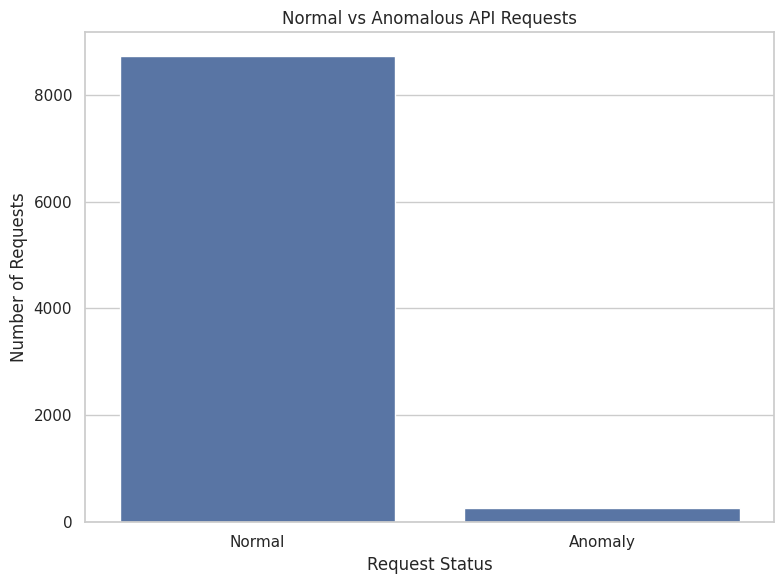

In [87]:
plt.figure(figsize=(8, 6))

sns.countplot(
    data=ml_df,
    x="anomaly_status"
)

plt.title("Normal vs Anomalous API Requests")
plt.xlabel("Request Status")
plt.ylabel("Number of Requests")

plt.tight_layout()
plt.show()

In [88]:
# Get anomalous records
anomalies_df = ml_df[
    ml_df["anomaly_prediction"] == -1
].copy()

# Sort by token consumption
high_token_anomalies = anomalies_df.sort_values(
    "total_tokens",
    ascending=False
)

display(
    high_token_anomalies[
        [
            "interaction_id",
            "model_name",
            "prompt_tokens",
            "completion_tokens",
            "total_tokens",
            "cost_usd",
            "anomaly_score"
        ]
    ].head(20)
)

,interaction_id,model_name,prompt_tokens,completion_tokens,total_tokens,cost_usd,anomaly_score
982,INT000983,claude-3.5-sonnet,1712,1042,2754,0.88128,0.054758
480,INT000481,llama-3.1-70b,1711,1024,2735,0.54700,0.011959
1213,INT001214,custom-local-8b,1669,1023,2692,0.01076,0.006700
7502,INT007503,llama-3.1-8b,1664,1024,2688,0.16128,0.006248
4031,INT004032,custom-local-8b,1827,849,2676,0.01072,0.011267
6799,INT006800,claude-3.5-sonnet,1742,931,2673,0.85536,0.043997
1840,INT001841,gpt-4.1,1578,1039,2617,1.04680,0.034112
7337,INT007338,gpt-4.1,1573,990,2563,1.02520,0.025147
70,INT000071,gpt-4.1,1660,900,2560,1.02400,0.026590
2901,INT002902,gpt-4o-mini,1699,858,2557,0.05112,0.022244


In [89]:
high_cost_anomalies = anomalies_df.sort_values(
    "cost_usd",
    ascending=False
)

display(
    high_cost_anomalies[
        [
            "interaction_id",
            "model_name",
            "model_provider",
            "total_tokens",
            "cost_usd",
            "latency_ms",
            "anomaly_score"
        ]
    ].head(20)
)

,interaction_id,model_name,model_provider,total_tokens,cost_usd,latency_ms,anomaly_score
1840,INT001841,gpt-4.1,openai,2617,1.04680,1788,0.034112
7337,INT007338,gpt-4.1,openai,2563,1.02520,2035,0.025147
70,INT000071,gpt-4.1,openai,2560,1.02400,1099,0.026590
6805,INT006806,gpt-4.1,openai,2547,1.01880,1400,0.068472
5621,INT005622,gpt-4.1,openai,2480,0.99200,399,0.085283
219,INT000220,gpt-4.1,openai,2470,0.98800,1253,0.045876
5053,INT005054,gpt-4.1,openai,2457,0.98280,1069,0.019646
2453,INT002454,gpt-4.1,openai,2432,0.97280,787,0.058515
446,INT000447,gpt-4.1,openai,2359,0.94360,1134,0.009775
5232,INT005233,gpt-4.1,openai,2327,0.93080,616,0.035664


In [90]:
high_latency_anomalies = anomalies_df.sort_values(
    "latency_ms",
    ascending=False
)

display(
    high_latency_anomalies[
        [
            "interaction_id",
            "model_name",
            "latency_ms",
            "tokens_per_second",
            "cost_usd",
            "anomaly_score"
        ]
    ].head(20)
)

,interaction_id,model_name,latency_ms,tokens_per_second,cost_usd,anomaly_score
4392,INT004393,claude-3.5-sonnet,3635,361.485557,0.42048,0.005831
3046,INT003047,mistral-large,3593,44.531033,0.01920,0.033070
3606,INT003607,gpt-4.1,3493,421.127970,0.58840,0.010414
281,INT000282,gpt-4.1,3477,232.096635,0.32280,0.029798
603,INT000604,llama-3.1-8b,3427,262.912168,0.05408,0.002325
88,INT000089,gpt-4o-mini,3391,317.900324,0.02156,0.005537
2751,INT002752,gpt-4o-mini,3345,503.139013,0.03368,0.013059
300,INT000301,gpt-4.1,3315,467.571644,0.62000,0.032636
677,INT000678,gemini-1.5-pro,3255,551.459293,0.57440,0.052778
6289,INT006290,llama-3.1-8b,3197,437.284955,0.08388,0.082194


In [91]:
model_anomaly_analysis = (
    ml_df.groupby("model_name")
    .agg(
        Total_Requests=("interaction_id", "count"),
        Anomalies=("anomaly_prediction",
                   lambda x: (x == -1).sum()),
        Total_Tokens=("total_tokens", "sum"),
        Total_Cost=("cost_usd", "sum")
    )
    .reset_index()
)

model_anomaly_analysis["Anomaly_Rate_Percentage"] = (
    model_anomaly_analysis["Anomalies"]
    / model_anomaly_analysis["Total_Requests"]
) * 100

model_anomaly_analysis = model_anomaly_analysis.sort_values(
    "Anomaly_Rate_Percentage",
    ascending=False
)

display(model_anomaly_analysis)

,model_name,Total_Requests,Anomalies,Total_Tokens,Total_Cost,Anomaly_Rate_Percentage
3,gpt-4.1,1089,88,1181396,472.55840,8.080808
0,claude-3.5-sonnet,1085,41,1192258,381.52256,3.778802
2,gemini-1.5-pro,1114,33,1218567,389.94144,2.962298
4,gpt-4o-mini,1158,31,1265778,25.31832,2.677029
1,custom-local-8b,1158,29,1259629,5.03928,2.504318
7,mistral-large,1090,19,1195366,143.44392,1.743119
5,llama-3.1-70b,1158,17,1275683,255.13660,1.468048
6,llama-3.1-8b,1148,12,1253796,75.22960,1.045296


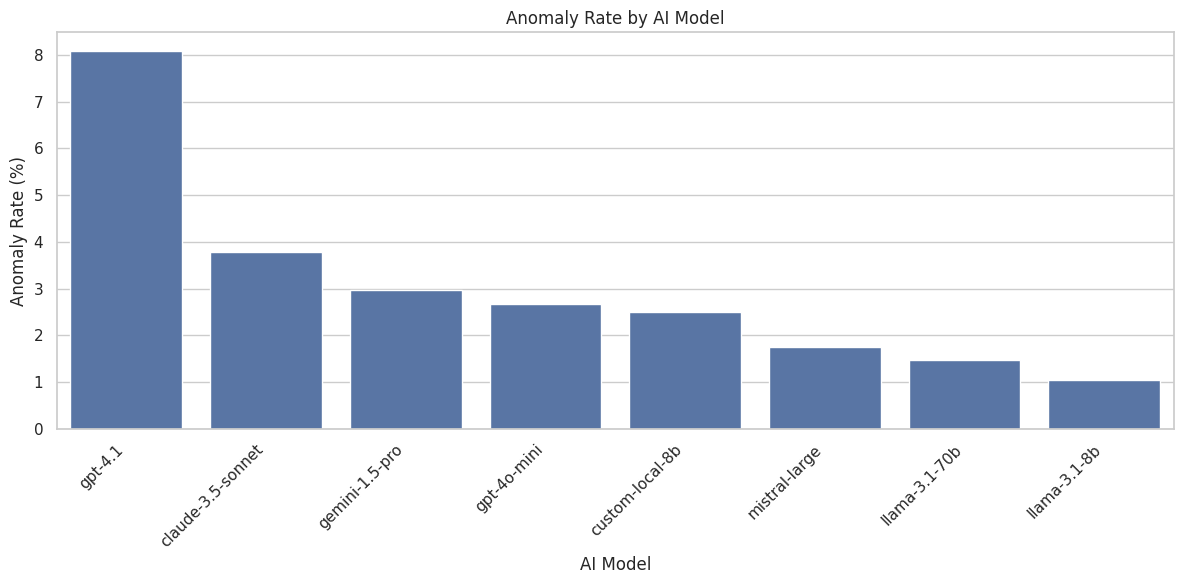

In [92]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=model_anomaly_analysis,
    x="model_name",
    y="Anomaly_Rate_Percentage"
)

plt.title("Anomaly Rate by AI Model")
plt.xlabel("AI Model")
plt.ylabel("Anomaly Rate (%)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [93]:
usecase_anomaly_analysis = (
    ml_df.groupby("use_case")
    .agg(
        Total_Requests=("interaction_id", "count"),
        Anomalies=("anomaly_prediction",
                   lambda x: (x == -1).sum()),
        Total_Tokens=("total_tokens", "sum"),
        Total_Cost=("cost_usd", "sum")
    )
    .reset_index()
)

usecase_anomaly_analysis["Anomaly_Rate_Percentage"] = (
    usecase_anomaly_analysis["Anomalies"]
    / usecase_anomaly_analysis["Total_Requests"]
) * 100

display(
    usecase_anomaly_analysis.sort_values(
        "Anomaly_Rate_Percentage",
        ascending=False
    )
)

,use_case,Total_Requests,Anomalies,Total_Tokens,Total_Cost,Anomaly_Rate_Percentage
3,customer_support,2723,104,2996979,533.31460,3.819317
1,coding_assistant,1681,56,1871808,335.88860,3.331350
2,content_writing,1441,44,1551684,268.94556,3.053435
4,data_analysis,1454,35,1574444,278.71732,2.407153
5,internal_qa,792,17,854338,154.71712,2.146465
0,brainstorming,909,14,993220,176.60692,1.540154


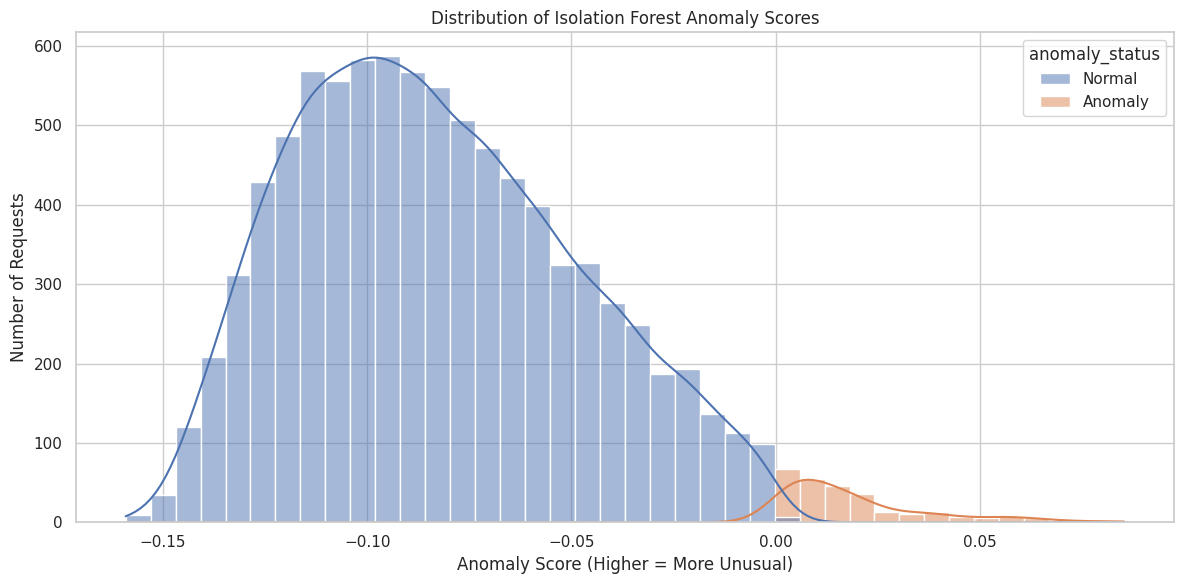

In [94]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data=ml_df,
    x="anomaly_score",
    hue="anomaly_status",
    bins=40,
    kde=True
)

plt.title("Distribution of Isolation Forest Anomaly Scores")
plt.xlabel("Anomaly Score (Higher = More Unusual)")
plt.ylabel("Number of Requests")

plt.tight_layout()
plt.show()

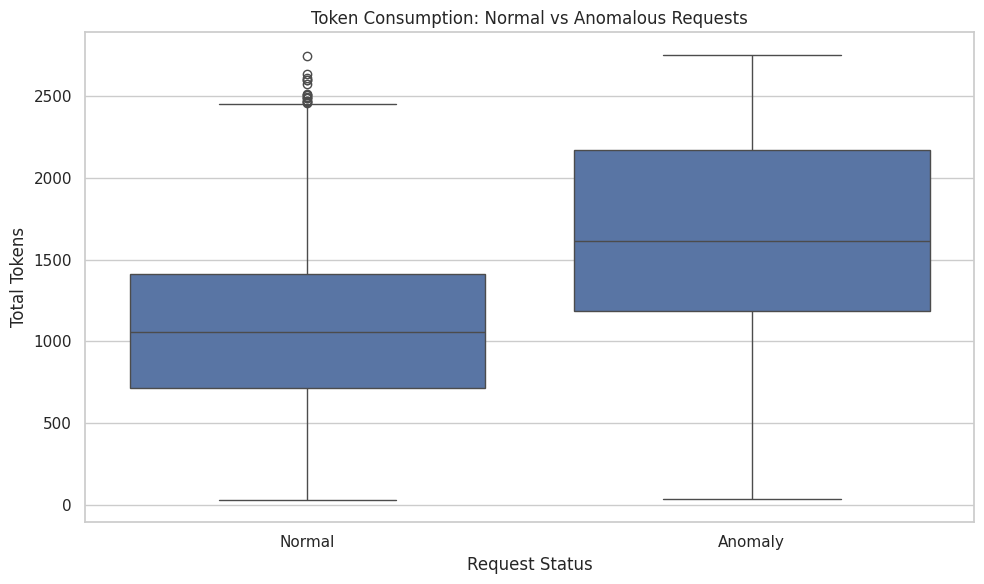

In [95]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=ml_df,
    x="anomaly_status",
    y="total_tokens"
)

plt.title("Token Consumption: Normal vs Anomalous Requests")
plt.xlabel("Request Status")
plt.ylabel("Total Tokens")

plt.tight_layout()
plt.show()

In [96]:
# Create investigation report
investigation_df = anomalies_df.copy()

# Dataset-based reference thresholds
token_threshold = ml_df["total_tokens"].quantile(0.95)
cost_threshold = ml_df["cost_usd"].quantile(0.95)
latency_threshold = ml_df["latency_ms"].quantile(0.95)

# Add investigation indicators
investigation_df["high_token_usage"] = (
    investigation_df["total_tokens"] > token_threshold
)

investigation_df["high_api_cost"] = (
    investigation_df["cost_usd"] > cost_threshold
)

investigation_df["high_latency"] = (
    investigation_df["latency_ms"] > latency_threshold
)

investigation_df["retry_activity"] = (
    investigation_df["retry_index"] > 0
)

investigation_df["high_tool_usage"] = (
    investigation_df["tool_calls_count"]
    > ml_df["tool_calls_count"].quantile(0.95)
)

display(
    investigation_df[
        [
            "interaction_id",
            "model_name",
            "total_tokens",
            "cost_usd",
            "latency_ms",
            "high_token_usage",
            "high_api_cost",
            "high_latency",
            "retry_activity",
            "high_tool_usage"
        ]
    ].head(20)
)

,interaction_id,model_name,total_tokens,cost_usd,latency_ms,high_token_usage,high_api_cost,high_latency,retry_activity,high_tool_usage
40,INT000041,custom-local-8b,1495,0.00600,487,False,False,False,True,False
63,INT000064,gpt-4o-mini,2220,0.04440,570,True,False,False,False,False
70,INT000071,gpt-4.1,2560,1.02400,1099,True,True,False,False,False
88,INT000089,gpt-4o-mini,1078,0.02156,3391,False,False,True,True,False
123,INT000124,gpt-4.1,1505,0.60200,435,False,True,False,False,False
140,INT000141,gemini-1.5-pro,2060,0.65920,2001,True,True,False,True,False
163,INT000164,gpt-4.1,573,0.22920,834,False,False,False,True,False
177,INT000178,gpt-4o-mini,2212,0.04424,1073,True,False,False,False,False
219,INT000220,gpt-4.1,2470,0.98800,1253,True,True,False,False,False
276,INT000277,gemini-1.5-pro,1936,0.61952,673,False,True,False,True,False


In [97]:
MODEL_PATH = (
    "/content/drive/MyDrive/Token-Analytics/models"
)

os.makedirs(MODEL_PATH, exist_ok=True)

model_file = os.path.join(
    MODEL_PATH,
    "isolation_forest_model.pkl"
)

joblib.dump(
    anomaly_pipeline,
    model_file
)

print("Machine learning model saved successfully!")
print(model_file)

Machine learning model saved successfully!
/content/drive/MyDrive/Token-Analytics/models/isolation_forest_model.pkl


In [98]:
ML_OUTPUT_PATH = (
    "/content/drive/MyDrive/Token-Analytics/reports/ml"
)

os.makedirs(ML_OUTPUT_PATH, exist_ok=True)

# Export complete dataset with anomaly predictions
ml_df.to_csv(
    os.path.join(
        ML_OUTPUT_PATH,
        "all_anomaly_predictions.csv"
    ),
    index=False
)

# Export only anomalous records
anomalies_df.to_csv(
    os.path.join(
        ML_OUTPUT_PATH,
        "detected_anomalies.csv"
    ),
    index=False
)

# Export model-level analysis
model_anomaly_analysis.to_csv(
    os.path.join(
        ML_OUTPUT_PATH,
        "model_anomaly_analysis.csv"
    ),
    index=False
)

# Export use-case analysis
usecase_anomaly_analysis.to_csv(
    os.path.join(
        ML_OUTPUT_PATH,
        "usecase_anomaly_analysis.csv"
    ),
    index=False
)

# Export investigation report
investigation_df.to_csv(
    os.path.join(
        ML_OUTPUT_PATH,
        "anomaly_investigation_report.csv"
    ),
    index=False
)

print("All machine learning reports exported!")
print("Output folder:", ML_OUTPUT_PATH)

All machine learning reports exported!
Output folder: /content/drive/MyDrive/Token-Analytics/reports/ml


In [99]:
print("=" * 55)
print("TOKEN ANALYTICS - ANOMALY DETECTION REPORT")
print("=" * 55)

print("Algorithm: Isolation Forest")

print("Total Requests:", total_records)

print("Normal Requests:", total_normal)

print("Detected Anomalies:", total_anomalies)

print("Anomaly Percentage:", round(anomaly_percentage, 2), "%")

print("Token Threshold (95th percentile):", token_threshold)

print("Cost Threshold (95th percentile):", round(cost_threshold, 6))

print("Latency Threshold (95th percentile):", latency_threshold)

print("=" * 55)

TOKEN ANALYTICS - ANOMALY DETECTION REPORT
Algorithm: Isolation Forest
Total Requests: 9000
Normal Requests: 8730
Detected Anomalies: 270
Anomaly Percentage: 3.0 %
Token Threshold (95th percentile): 1973.0
Cost Threshold (95th percentile): 0.5712
Latency Threshold (95th percentile): 2309.0


In [100]:

from pathlib import Path

# Google Drive project folders
PROJECT_PATH = Path("/content/drive/MyDrive/Token-Analytics")

ML_PATH = PROJECT_PATH / "reports" / "ml"

OUTPUT_PATH = PROJECT_PATH / "reports" / "business_insights"

OUTPUT_PATH.mkdir(parents=True, exist_ok=True)

# Load Phase 5 anomaly predictions
ml_df = pd.read_csv(
    ML_PATH / "all_anomaly_predictions.csv"
)

print("Dataset loaded successfully!")
print("Dataset shape:", ml_df.shape)

display(ml_df.head())

Dataset loaded successfully!
Dataset shape: (9000, 71)


,interaction_id,session_id,user_id,timestamp_utc,split,channel,use_case,country_code,region,account_tier,segment,instruction_template,model_provider,model_name,temperature,top_p,max_tokens,prompt_tokens,completion_tokens,total_tokens,latency_ms,cost_usd,response_quality_score,is_failure,failure_type,hallucination_flag,toxicity_flag,safety_block_flag,formatting_error_flag,tool_error_flag,latency_timeout_flag,tool_calls_count,tools_used,user_feedback_score,user_feedback_label,user_reported_issue,retry_index,repair_strategy,final_resolution_state,business_impact_tag,request_text,response_text_snippet,tokens_per_second,date_utc,hour_of_day_utc,day_of_week,is_weekend,is_peak_hour,prompt_to_completion_ratio,request_text_template,instruction_text,user_feedback_observed,prompt_id,response_text_snippet_len_chars,response_text_snippet_is_truncated,calculated_total_tokens,token_mismatch,year,month,month_name,hour,input_token_percentage,output_token_percentage,cost_per_1000_tokens,prompt_completion_ratio,hour_sin,hour_cos,weekend_numeric,anomaly_prediction,anomaly_score,anomaly_status
0,INT000001,S01207,U00013,2025-03-25 11:14:35+00:00,train,web_app,coding_assistant,BR,AMER,pro,enterprise_team,creative_writer,meta,llama-3.1-70b,0.257,0.898,768,186,422,608,615,0.12160,0.846,False,none,False,False,False,False,False,False,0,none,2.0,positive,False,0,none,auto_resolved,medium,Can you help me debug this? I'm getting a Pyth...,Let's turn this into a reliable workflow. Goal...,988.617886,2025-03-25,11,1,False,True,0.4408,I'm getting a Python error: `NullPointerExcept...,You are a senior software engineer helping use...,True,83c939e9b891e505ac06548e158556e919317a64,216,True,608,False,2025,3,March,11,30.592105,69.407895,0.20,0.440758,0.258819,-0.965926,0,1,-0.134469,Normal
1,INT000002,S01119,U00017,2025-02-23 04:08:56+00:00,val,mobile_app,customer_support,IN,APAC,free,individual,general_assistant,anthropic,claude-3.5-sonnet,0.806,0.890,768,701,410,1111,1194,0.35552,0.352,True,formatting_error,False,False,False,True,False,False,0,none,NaN,no_feedback,False,0,enable_tools,escalated_to_human,high,I'm stuck on this and need some guidance: Our ...,Let's break this down into actionable steps. S...,930.485762,2025-02-23,4,6,True,False,1.7098,Our customer is getting an error when trying t...,You are a helpful customer support assistant f...,False,a52fb80193c7c0769c0836852624f4b025a04d2a,207,True,1111,False,2025,2,February,4,63.096310,36.903690,0.32,1.709756,0.866025,0.500000,1,1,-0.067602,Normal
2,INT000003,S00653,U00155,2025-02-25 17:31:08+00:00,train,web_app,brainstorming,GB,EMEA,free,team,code_assistant_secure,google,gemini-1.5-pro,0.412,0.898,1024,425,131,556,1196,0.17792,0.543,True,safety_block,False,False,True,False,False,False,0,none,NaN,no_feedback,False,0,manual_post_edit,abandoned,low,Context for you: Brainstorm taglines for a pro...,This is a common pattern; the fix is straightf...,464.882943,2025-02-25,17,1,False,True,3.2443,Brainstorm taglines for a productivity app tha...,You are a creative assistant helping users exp...,False,9886b059d7fa547dc6fd91d4a5c80abdb317022d,223,True,556,False,2025,2,February,17,76.438849,23.561151,0.32,3.244275,-0.965926,-0.258819,0,1,-0.128340,Normal
3,INT000004,S00103,U00263,2025-03-14 17:42:16+00:00,train,web_app,content_writing,AU,APAC,free,team,creative_writer,google,gemini-1.5-pro,0.637,0.822,1024,1173,545,1718,1266,0.54976,0.888,False,none,False,False,False,False,False,False,0,none,NaN,no_feedback,False,0,none,auto_resolved,high,I'm working on something and need help: Draft ...,Here's what I'd implement in production. Goal:...,1357.030016,2025-03-14,17,4,False,True,2.1523,Draft a friendly email announcing a small pric...,You are a writing assistant helping users craf...,False,469eb15f8b08d9b4130e14a6c3888f14e335a854,236,True,1718,False,2025,3,March,17,68.277066,31.722934,0.32,2.152294,-0.965926,-0.258819,0,1,-0.099700,Normal
4,INT000005,S01553,U00118,2025-02-24 00:39:04+00:00,train,api,data_analysis,IN,APAC,

In [101]:
# Convert timestamp
ml_df["timestamp_utc"] = pd.to_datetime(
    ml_df["timestamp_utc"],
    errors="coerce",
    utc=True
)

# Calculate overall KPIs
total_requests = len(ml_df)

total_tokens = ml_df["total_tokens"].sum()

total_cost = ml_df["cost_usd"].sum()

average_latency = ml_df["latency_ms"].mean()

average_quality = ml_df["response_quality_score"].mean()

# Handle boolean or 0/1 failure values
failure_flag = ml_df["is_failure"].astype(str).str.lower().isin(
    ["true", "1", "yes"]
)

failed_requests = failure_flag.sum()

failure_rate = (
    failed_requests / total_requests * 100
    if total_requests else 0
)

anomaly_count = (
    ml_df["anomaly_status"].eq("Anomaly").sum()
)

anomaly_rate = (
    anomaly_count / total_requests * 100
    if total_requests else 0
)

business_kpis = pd.DataFrame({
    "Metric": [
        "Total Requests",
        "Total Tokens",
        "Total Estimated Cost (USD)",
        "Average Latency (ms)",
        "Average Response Quality",
        "Failed Requests",
        "Failure Rate (%)",
        "Detected Anomalies",
        "Anomaly Rate (%)"
    ],
    "Value": [
        total_requests,
        total_tokens,
        total_cost,
        average_latency,
        average_quality,
        failed_requests,
        failure_rate,
        anomaly_count,
        anomaly_rate
    ]
})

display(business_kpis.round(2))

business_kpis.to_csv(
    OUTPUT_PATH / "overall_business_kpis.csv",
    index=False
)

,Metric,Value
0,Total Requests,9000.00
1,Total Tokens,9842473.00
2,Total Estimated Cost (USD),1748.19
3,Average Latency (ms),1215.25
4,Average Response Quality,0.72
5,Failed Requests,2557.00
6,Failure Rate (%),28.41
7,Detected Anomalies,270.00
8,Anomaly Rate (%),3.00


In [102]:
model_analysis = (
    ml_df.groupby("model_name")
    .agg(
        total_requests=("interaction_id", "count"),
        total_tokens=("total_tokens", "sum"),
        total_cost=("cost_usd", "sum"),
        average_latency=("latency_ms", "mean"),
        average_quality=("response_quality_score", "mean"),
        failed_requests=("is_failure", "sum")
    )
    .reset_index()
)

model_analysis["cost_per_1000_tokens"] = (
    model_analysis["total_cost"] /
    model_analysis["total_tokens"].replace(0, np.nan)
) * 1000

model_analysis = model_analysis.sort_values(
    "total_cost",
    ascending=False
)

display(model_analysis.round(3))

model_analysis.to_csv(
    OUTPUT_PATH / "model_business_analysis.csv",
    index=False
)

,model_name,total_requests,total_tokens,total_cost,average_latency,average_quality,failed_requests,cost_per_1000_tokens
3,gpt-4.1,1089,1181396,472.558,1221.167,0.725,295,0.400
2,gemini-1.5-pro,1114,1218567,389.941,1191.527,0.725,316,0.320
0,claude-3.5-sonnet,1085,1192258,381.523,1242.034,0.720,321,0.320
5,llama-3.1-70b,1158,1275683,255.137,1192.372,0.723,329,0.200
7,mistral-large,1090,1195366,143.444,1204.374,0.727,305,0.120
6,llama-3.1-8b,1148,1253796,75.230,1220.916,0.731,307,0.060
4,gpt-4o-mini,1158,1265778,25.318,1204.275,0.723,328,0.020
1,custom-local-8b,1158,1259629,5.039,1245.863,0.716,356,0.004


In [103]:
usecase_analysis = (
    ml_df.groupby("use_case")
    .agg(
        total_requests=("interaction_id", "count"),
        total_tokens=("total_tokens", "sum"),
        total_cost=("cost_usd", "sum"),
        average_latency=("latency_ms", "mean"),
        failed_requests=("is_failure", "sum")
    )
    .reset_index()
)

usecase_analysis["failure_rate"] = (
    usecase_analysis["failed_requests"] /
    usecase_analysis["total_requests"] * 100
)

usecase_analysis = usecase_analysis.sort_values(
    "total_cost",
    ascending=False
)

display(usecase_analysis.round(2))

usecase_analysis.to_csv(
    OUTPUT_PATH / "usecase_business_analysis.csv",
    index=False
)

,use_case,total_requests,total_tokens,total_cost,average_latency,failed_requests,failure_rate
3,customer_support,2723,2996979,533.31,1210.43,732,26.88
1,coding_assistant,1681,1871808,335.89,1215.02,650,38.67
4,data_analysis,1454,1574444,278.72,1249.69,505,34.73
2,content_writing,1441,1551684,268.95,1201.17,273,18.95
0,brainstorming,909,993220,176.61,1217.33,145,15.95
5,internal_qa,792,854338,154.72,1192.28,252,31.82


In [104]:
hourly_analysis = (
    ml_df.groupby("hour_of_day_utc")
    .agg(
        total_requests=("interaction_id", "count"),
        total_tokens=("total_tokens", "sum"),
        total_cost=("cost_usd", "sum")
    )
    .reset_index()
    .sort_values("total_requests", ascending=False)
)

display(hourly_analysis)

hourly_analysis.to_csv(
    OUTPUT_PATH / "peak_usage_analysis.csv",
    index=False
)

,hour_of_day_utc,total_requests,total_tokens,total_cost
10,10,708,763912,134.93848
16,16,684,762070,138.98960
9,9,666,711042,131.95244
15,15,648,701053,119.62148
8,8,605,669678,123.11664
14,14,469,512801,81.89092
7,7,441,475042,82.88028
17,17,437,463849,87.49636
11,11,402,455172,82.64368
13,13,382,416619,76.41084


In [105]:
anomaly_analysis = (
    ml_df[ml_df["anomaly_status"] == "Anomaly"]
    .groupby("model_name")
    .agg(
        anomaly_count=("interaction_id", "count"),
        anomaly_tokens=("total_tokens", "sum"),
        anomaly_cost=("cost_usd", "sum"),
        average_anomaly_score=("anomaly_score", "mean")
    )
    .reset_index()
    .sort_values("anomaly_count", ascending=False)
)

display(anomaly_analysis)

anomaly_analysis.to_csv(
    OUTPUT_PATH / "anomaly_business_analysis.csv",
    index=False
)

,model_name,anomaly_count,anomaly_tokens,anomaly_cost,average_anomaly_score
3,gpt-4.1,88,138174,55.26960,0.019465
0,claude-3.5-sonnet,41,68846,22.03072,0.016526
2,gemini-1.5-pro,33,54124,17.31968,0.018724
4,gpt-4o-mini,31,47173,0.94364,0.019345
1,custom-local-8b,29,42937,0.17176,0.017180
7,mistral-large,19,25680,3.08160,0.017958
5,llama-3.1-70b,17,32795,6.55900,0.020312
6,llama-3.1-8b,12,20457,1.22744,0.019368


In [106]:
# Identify important findings

highest_cost_model = model_analysis.iloc[0]

highest_token_model = model_analysis.loc[
    model_analysis["total_tokens"].idxmax()
]

highest_cost_usecase = usecase_analysis.iloc[0]

highest_usage_hour = hourly_analysis.iloc[0]

# Generate findings
findings = [
    f"Total AI interactions analysed: {total_requests:,}.",

    f"Total token consumption: {total_tokens:,.0f} tokens.",

    f"Total estimated AI cost: ${total_cost:,.2f}.",

    f"Model with highest estimated cost: "
    f"{highest_cost_model['model_name']}.",

    f"Model with highest token consumption: "
    f"{highest_token_model['model_name']}.",

    f"Highest-cost use case: "
    f"{highest_cost_usecase['use_case']}.",

    f"Busiest UTC hour: "
    f"{int(highest_usage_hour['hour_of_day_utc'])}:00.",

    f"Detected unusual interactions: {anomaly_count:,}.",

    f"Overall failure rate: {failure_rate:.2f}%."
]

for number, finding in enumerate(findings, 1):
    print(f"{number}. {finding}")

1. Total AI interactions analysed: 9,000.
2. Total token consumption: 9,842,473 tokens.
3. Total estimated AI cost: $1,748.19.
4. Model with highest estimated cost: gpt-4.1.
5. Model with highest token consumption: llama-3.1-70b.
6. Highest-cost use case: customer_support.
7. Busiest UTC hour: 10:00.
8. Detected unusual interactions: 270.
9. Overall failure rate: 28.41%.


In [107]:
# Save the final business analysis reports

reports = {
    "overall_business_kpis.csv": business_kpis,
    "model_business_analysis.csv": model_analysis,
    "usecase_business_analysis.csv": usecase_analysis,
    "peak_usage_analysis.csv": hourly_analysis,
    "anomaly_business_analysis.csv": anomaly_analysis
}

for filename, report in reports.items():
    report.to_csv(
        OUTPUT_PATH / filename,
        index=False
    )

print("All business analysis reports exported successfully!")

print("Output folder:", OUTPUT_PATH)

All business analysis reports exported successfully!
Output folder: /content/drive/MyDrive/Token-Analytics/reports/business_insights
